# EE48009 — Assignment 1
## Channel Estimation and Pilot Overhead with Sionna

Structure (follows the assignment text step by step):

| Step | What | Where |
|---|---|---|
| 1-3 | scene, BS (M x M UPA, M = 1, 2, 4), UE grid, mobility, spatial split (+ radio map and 3-D grid picture) | first cells |
| 4 | ray tracing, OFDM channels, delay spread / Bc / Tc statistics, saved dataset | "Step 4" |
| 5 | NR and custom pilot patterns, overhead table, Nyquist predictions | "Step 5" |
| 6 | LS-nn, LS-lin, LMMSE (site), LMMSE (TDL), perfect CSI | "Step 6" |
| 7 | learned estimators: learned linear filter and CNN, parameters / latency | "Step 7" |
| 8 | BLER, goodput, R(eta), eta*, M = 1, 2, 4 comparison | "Step 8" |
| 9 | reduced-pilot study, speed and site mismatch | "Step 9" |
| EE58009 | theory extension: degrees of freedom D and eta* | after Step 9 |

Practical notes: use a **GPU runtime**; the ray-traced dataset is cached in `channel_dataset_4x4.pt` (delete it to regenerate);
the link-level cells are the slowest, lower `MAX_SLOTS` for a quick test.

In [1]:
%pip install -q "sionna==2.2.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.


In [2]:
!pip install --force-reinstall "numpy<2.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 49.6 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.



## Step 1: Scenario Selection

For this assignment, we selected the built-in San Francisco scene provided by Sionna RT. The environment contains an urban layout with multiple buildings, streets, and obstacles that can affect wireless signal propagation.

The urban layout provides an useful environment for examining how multipath propagation and doppler shifts affect channel estimation and pilot overhead.

The presence of buildings and streets can create both Los and NLoS propagation paths. Therefore multipath propagation can produce frequency selective channels. The delay spread is expected to vary across UE locations depending on surrounding buildings and whether direct propagation paths are available.

UE mobility will also produce Doppler shifts, causing the wireless channel to change over time and allowing us to study the impact of time selectivity on channel estimation.


In [3]:
import sionna
import numpy as np
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera, \
                      PathSolver, RadioMapSolver, subcarrier_frequencies

scene = load_scene(sionna.rt.scene.san_francisco)
scene.frequency = 3.5e9

Scene center: [102.69644165  -4.18571472  85.31410217]
Scene dimensions: [1221.70318604  927.69338989  170.62820435]


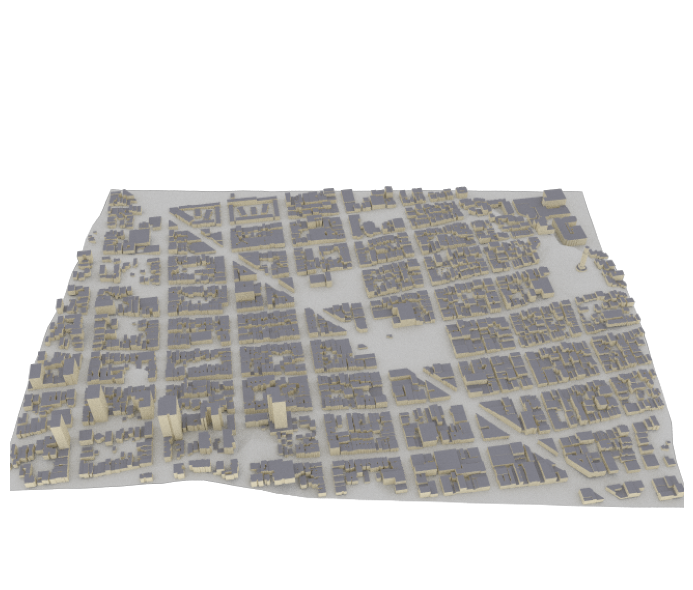

In [4]:
#Obtain the bounding box for the scene
bbox = scene.mi_scene.bbox()

#Minimum and maximum coordinates
p_min = np.array(bbox.min, dtype=float)
p_max = np.array(bbox.max, dtype=float)

#Calculate the scene center and dimensions
center = (p_min + p_max) / 2
size = p_max - p_min

print("Scene center:", center)
print("Scene dimensions:", size)

#Automatically position the camera
camera_position = center + np.array([0.0, -1 * max(size[0], size[1]), 1 * max(size[0], size[1])])

auto_cam = Camera(
    position=camera_position.tolist(),
    look_at=center.tolist()
)

scene.render(
    camera=auto_cam,
    resolution=[650, 550],
    num_samples=128
);


## Step 2 — Base Station and UE Configuration

### 2.1 Antenna Array Configuration

In [5]:

from sionna.rt import PlanarArray

#Creating a single transmit antenna of UE
scene.tx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V"
)

#BS: M x M receive antenna array
M = 1  #M will take values 1,2 and 4.

scene.rx_array = PlanarArray(
    num_rows=M,
    num_cols=M,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="tr38901",
    polarization="V"
)

print(f"UE antennas: 1")
print(f"BS array: {M} x {M}")
print(f"BS antenna elements: {M**2}")


UE antennas: 1
BS array: 1 x 1
BS antenna elements: 1


### 2.2 Base Station Placement

The base station is positioned on the Coit Tower in the San Francisco scene. This elevated location was selected using Blender to provide coverage over the surrounding urban environment.


In [6]:

from sionna.rt import Transmitter, Receiver

bs_position = [266.734, 130.195, 49.5552]

bs = Receiver(
    name="bs",
    position=bs_position
)

scene.add(bs)

print("BS position:", bs.position)



BS position: [[266.734, 130.195, 49.5552]]


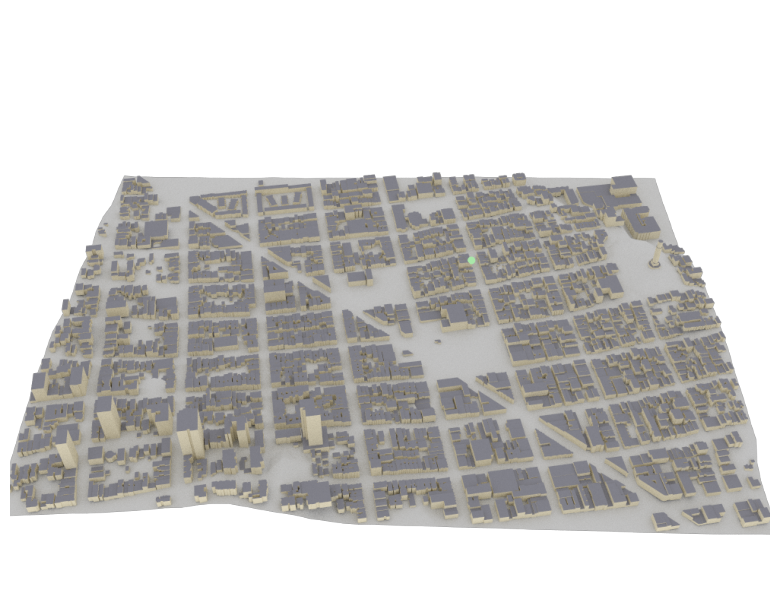

In [7]:

#This cell visualises the BS.

scene.render(
    camera=auto_cam,
    show_devices=True,
    resolution=[1000, 750],
    num_samples=128
);


##STEP 3.1 Define UE coverage region

In [8]:
import numpy as np

#200x200 region
center_x = 465.0
center_y = 95.0

region_size = 200.0
grid_spacing = 10.0

rotation_deg = 10.0
rotation_rad = np.deg2rad(rotation_deg)

ue_region_center = [center_x, center_y]

print("Region center:", ue_region_center)
print("Dimensions:", region_size, "x", region_size, "m")
print("Rotation:", rotation_deg, "degrees")



Region center: [465.0, 95.0]
Dimensions: 200.0 x 200.0 m
Rotation: 10.0 degrees


##Step 3.2 Prepare terrain following UE positions

In [9]:
import numpy as np
from sionna.rt import transform_mesh

#Copy the San Francisco terrain
measurement_surface = scene.objects["Terrain"].clone(
    as_mesh=True
)

#Raise it by 1.5 meters to represent UE height
transform_mesh(
    measurement_surface,
    translation=np.array([0, 0, 1.5])
)

print("UE measurement surface created.")


UE measurement surface created.


##Step 3.3 Generate 2D candidate UE positions

In [10]:

# Step 3.3 — Generate rotated 2D UE grid

local_values = np.arange(
    -region_size / 2,
    region_size / 2 + 0.01,
    grid_spacing
)

# Local coordinates before rotation
U, V = np.meshgrid(local_values, local_values)

# Rotate into world coordinates
X = (
    center_x
    + U * np.cos(rotation_rad)
    - V * np.sin(rotation_rad)
)

Y = (
    center_y
    + U * np.sin(rotation_rad)
    + V * np.cos(rotation_rad)
)

# Global XY coordinates used by Sionna
ue_xy = np.column_stack((X.ravel(), Y.ravel()))

# Local coordinates used for train/val/test splitting
ue_local = np.column_stack((U.ravel(), V.ravel()))

print("Candidate UE locations:", len(ue_xy))
print("First five positions:")
print(ue_xy[:5])



Candidate UE locations: 441
First five positions:
[[383.88404247 -20.84559307]
 [393.73212    -19.10911129]
 [403.58019753 -17.37262951]
 [413.42827506 -15.63614774]
 [423.27635259 -13.89966596]]


This is the square.

## Step 3.4 Assign UE heights using the terrain

In [11]:
import mitsuba as mi

terrain_scene = mi.load_dict({
    "type": "scene",
    "terrain": measurement_surface
})

ue_positions = []
terrain_grid_indices = []
missing_terrain = []

ray_start_z = 1000.0

for grid_idx, (x, y) in enumerate(ue_xy):

    ray = mi.Ray3f(
        o=mi.Point3f(float(x), float(y), ray_start_z),
        d=mi.Vector3f(0.0, 0.0, -1.0)
    )

    hit = terrain_scene.ray_intersect(ray)

    if bool(np.asarray(hit.is_valid()).item()):

        z = float(np.asarray(hit.p.z).item())

        ue_positions.append([float(x), float(y), z])
        terrain_grid_indices.append(grid_idx)

    else:
        missing_terrain.append([float(x), float(y)])

ue_positions = np.array(ue_positions).reshape(-1, 3)
terrain_grid_indices = np.array(
    terrain_grid_indices, dtype=int
)

print("Candidates:", len(ue_xy))
print("Terrain intersections:", len(ue_positions))
print("Missing terrain:", len(missing_terrain))



Candidates: 441
Terrain intersections: 441
Missing terrain: 0


## Step 3.5 Filter indoor UE positions

In [12]:

# Step 3.5 — Filter likely indoor UE locations

outdoor_positions = []
blocked_positions = []

outdoor_grid_indices = []

for idx, pos in enumerate(ue_positions):

    x, y, z = pos

    ray = mi.Ray3f(
        o=mi.Point3f(
            float(x),
            float(y),
            float(z + 0.05)
        ),
        d=mi.Vector3f(0.0, 0.0, 1.0)
    )

    hit = scene.mi_scene.ray_test(ray)
    is_blocked = bool(np.asarray(hit).item())

    if is_blocked:
        blocked_positions.append(pos)
    else:
        outdoor_positions.append(pos)

        # Remember the original rotated-grid index
        outdoor_grid_indices.append(
            terrain_grid_indices[idx]
        )

outdoor_positions = np.array(
    outdoor_positions
).reshape(-1, 3)

blocked_positions = np.array(
    blocked_positions
).reshape(-1, 3)

outdoor_grid_indices = np.array(
    outdoor_grid_indices, dtype=int
)

# Matching local coordinates for surviving UE points
outdoor_local = ue_local[outdoor_grid_indices]

print("Total positions:", len(ue_positions))
print("Outdoor candidates:", len(outdoor_positions))
print("Excluded:", len(blocked_positions))



Total positions: 441
Outdoor candidates: 236
Excluded: 205


In [13]:

# Step 2 — Aim BS toward final UE region

region_center_xy = np.array(ue_region_center)

distances = np.linalg.norm(
    outdoor_positions[:, :2] - region_center_xy,
    axis=1
)

closest_idx = np.argmin(distances)

aim_point = outdoor_positions[closest_idx]

bs = scene.get("bs")
bs.look_at(aim_point.tolist())

print("BS position:", bs.position)
print("New target:", aim_point)
print("BS orientation:", bs.orientation)



BS position: [[266.734, 130.195, 49.5552]]
New target: [465.          95.          52.64714432]
BS orientation: [[-0.175684, -0.0153537, 0]]


##Step 3.6 UE Velocities

In [14]:
# Same random direction for all speeds at a given location

rng = np.random.default_rng(42)

speeds_kmh = [3, 30, 120]
ue_dataset = []

for location_id, position in enumerate(outdoor_positions):

    # One random direction per UE location
    theta = rng.uniform(0, 2 * np.pi)

    for speed_kmh in speeds_kmh:

        speed_ms = speed_kmh / 3.6

        velocity = speed_ms * np.array([
            np.cos(theta),
            np.sin(theta),
            0.0
        ])

        ue_dataset.append({
            "location_id": location_id,
            "position": position.copy(),
            "speed_kmh": speed_kmh,
            "velocity": velocity,
            "direction_rad": theta
        })

print("Total channel cases:", len(ue_dataset))

for sample in ue_dataset[:3]:
    print(sample)


Total channel cases: 708
{'location_id': 0, 'position': array([383.88404247, -20.84559307,  32.47031021]), 'speed_kmh': 3, 'velocity': array([ 0.12496047, -0.82391099,  0.        ]), 'direction_rad': 4.862909272689599}
{'location_id': 0, 'position': array([383.88404247, -20.84559307,  32.47031021]), 'speed_kmh': 30, 'velocity': array([ 1.24960469, -8.23910994,  0.        ]), 'direction_rad': 4.862909272689599}
{'location_id': 0, 'position': array([383.88404247, -20.84559307,  32.47031021]), 'speed_kmh': 120, 'velocity': array([  4.99841874, -32.95643975,   0.        ]), 'direction_rad': 4.862909272689599}


#Step 3.8 Spatially disjoint dataset split

In [15]:

# Step 3.8 — Spatial split in rotated local coordinates

location_splits = {}

for location_id, local_position in enumerate(outdoor_local):

    u, v = local_position

    if v >= 0.0:
        split = "train"

    elif -50.0 <= v <= -20.0:
        split = "validation"

    elif v <= -70.0:
        split = "test"

    else:
        split = "buffer"

    location_splits[location_id] = split

# Assign all three speeds at a location to the same split
for sample in ue_dataset:
    sample["split"] = location_splits[sample["location_id"]]

train_data = [
    s for s in ue_dataset if s["split"] == "train"
]

val_data = [
    s for s in ue_dataset if s["split"] == "validation"
]

test_data = [
    s for s in ue_dataset if s["split"] == "test"
]

from collections import Counter

counts = Counter(location_splits.values())

print("Location counts:", counts)
print("Training channel cases:", len(train_data))
print("Validation channel cases:", len(val_data))
print("Test channel cases:", len(test_data))

assert len(location_splits) == len(outdoor_positions)
assert sum(counts.values()) == len(outdoor_positions)



Location counts: Counter({'train': 131, 'test': 49, 'validation': 39, 'buffer': 17})
Training channel cases: 393
Validation channel cases: 117
Test channel cases: 147


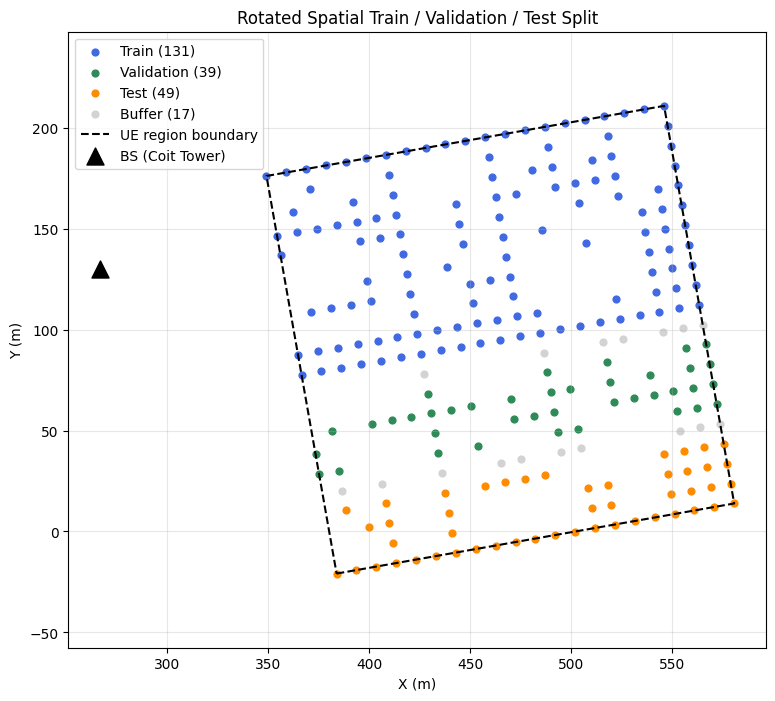

In [16]:

# Step 3.9 — Visualize rotated spatial dataset split

import matplotlib.pyplot as plt

colors = {
    "train": "royalblue",
    "validation": "seagreen",
    "test": "darkorange",
    "buffer": "lightgray"
}

plt.figure(figsize=(9, 8))

for split, color in colors.items():

    positions = np.array([
        position
        for location_id, position in enumerate(outdoor_positions)
        if location_splits[location_id] == split
    ]).reshape(-1, 3)

    if len(positions) > 0:
        plt.scatter(
            positions[:, 0],
            positions[:, 1],
            color=color,
            s=24,
            label=f"{split.capitalize()} ({len(positions)})"
        )

# Draw rotated square boundary
corners_local = np.array([
    [-100, -100],
    [100, -100],
    [100, 100],
    [-100, 100],
    [-100, -100]
])

c = np.cos(rotation_rad)
s = np.sin(rotation_rad)

corners_global = np.column_stack((
    center_x + corners_local[:, 0]*c - corners_local[:, 1]*s,
    center_y + corners_local[:, 0]*s + corners_local[:, 1]*c
))

plt.plot(
    corners_global[:, 0],
    corners_global[:, 1],
    color="black",
    linewidth=1.5,
    linestyle="--",
    label="UE region boundary"
)

bs_xyz = bs.position.numpy().reshape(-1)

plt.scatter(
    bs_xyz[0], bs_xyz[1],
    color="black",
    marker="^",
    s=150,
    label="BS (Coit Tower)"
)

plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.title("Rotated Spatial Train / Validation / Test Split")

plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


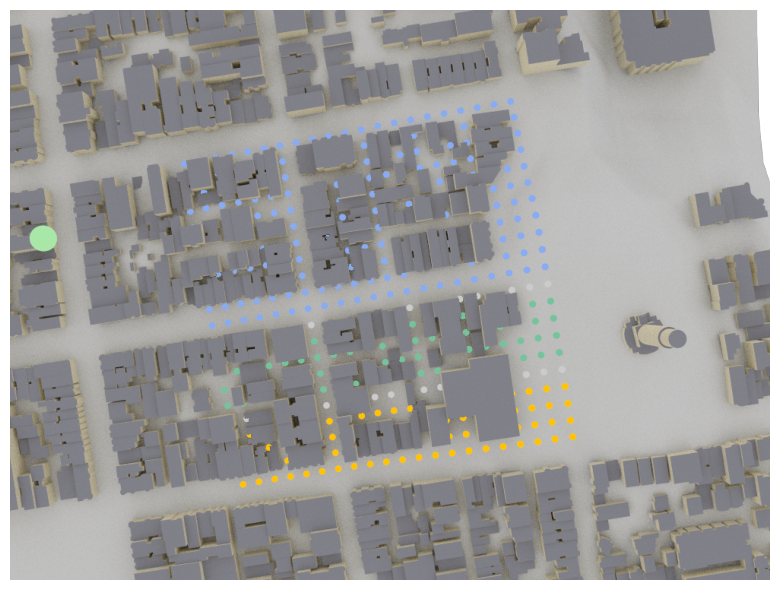

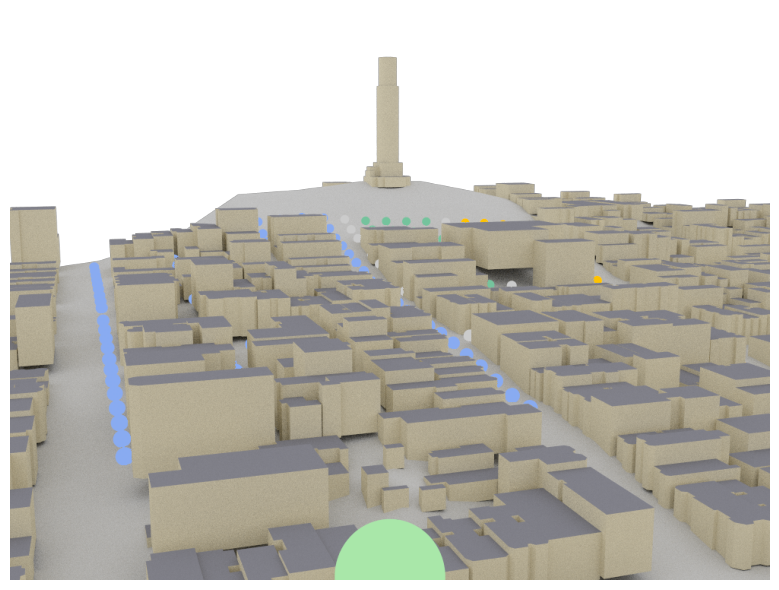

In [17]:
# ---- Visualise the UE grid and the BS on the actual 3-D scene ----
splits_vis = np.array([location_splits[i] for i in range(len(outdoor_positions))])
split_colors = {"train": (0.25, 0.41, 0.88), "validation": (0.18, 0.55, 0.34), "test": (1.0, 0.55, 0.0), "buffer": (0.6, 0.6, 0.6)}

viz_names = []
for i, (p, s) in enumerate(zip(outdoor_positions, splits_vis)):
    name = f"viz_{i}"
    try:
        scene.add(Transmitter(name=name, position=[float(x) for x in p], color=split_colors[s], display_radius=2.0))
    except TypeError:                                   # older API without color / display_radius
        scene.add(Transmitter(name=name, position=[float(x) for x in p]))
    viz_names.append(name)

grid_center = outdoor_positions.mean(0)
bs_xyz = scene.get("bs").position.numpy().reshape(-1)

try:
    top_cam = Camera(position=[float(grid_center[0]), float(grid_center[1]) - 1.0, 600.0],
                     look_at=[float(grid_center[0]), float(grid_center[1]), 0.0])
    scene.render(camera=top_cam, show_devices=True, resolution=(1000, 750), num_samples=128);

    hd = (bs_xyz - grid_center) * np.array([1, 1, 0]); hd = hd / (np.linalg.norm(hd) + 1e-9)
    side_cam = Camera(position=(bs_xyz + hd * 120 + np.array([0, 0, 60])).tolist(), look_at=grid_center.tolist())
    scene.render(camera=side_cam, show_devices=True, resolution=(1000, 750), num_samples=128);
finally:
    for n in viz_names: scene.remove(n)                 # always clean up: these markers must not be traced later

### 3.10 Radio map — signal strength in the scene (Sionna `RadioMapSolver`)

The BS is added as a temporary transmitter (path gain is reciprocal, so uplink and downlink give the same map). The map is computed on the
terrain-following measurement surface at UE height (1.5 m); if the installed Sionna version does not accept a measurement surface the cell
falls back to a flat map plane. Path gain shows where buildings shadow the BS, which explains the LoS / NLoS split and the UEs without paths.

radio map computed
path gain range: -142 ... -67 dB
radio_map.show() not available for this map type ( AttributeError("'MeshRadioMap' object has no attribute 'show'") ) - the renders above show the map.


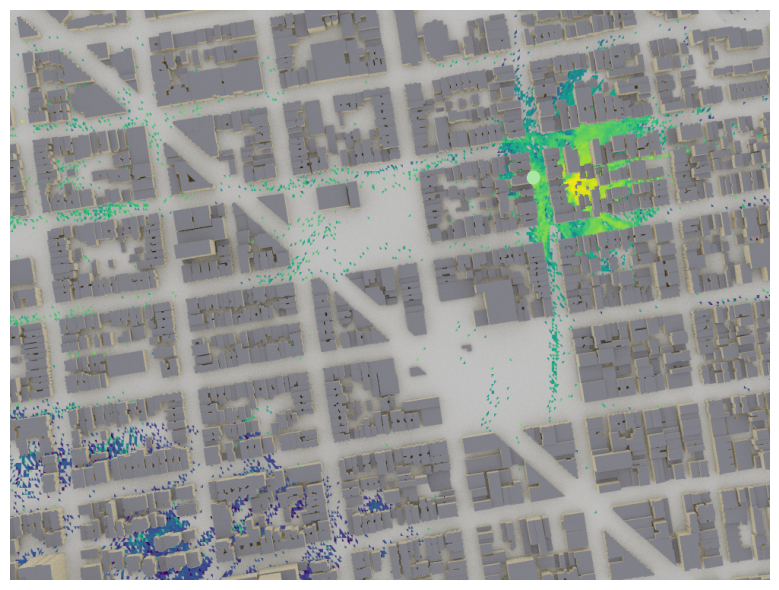

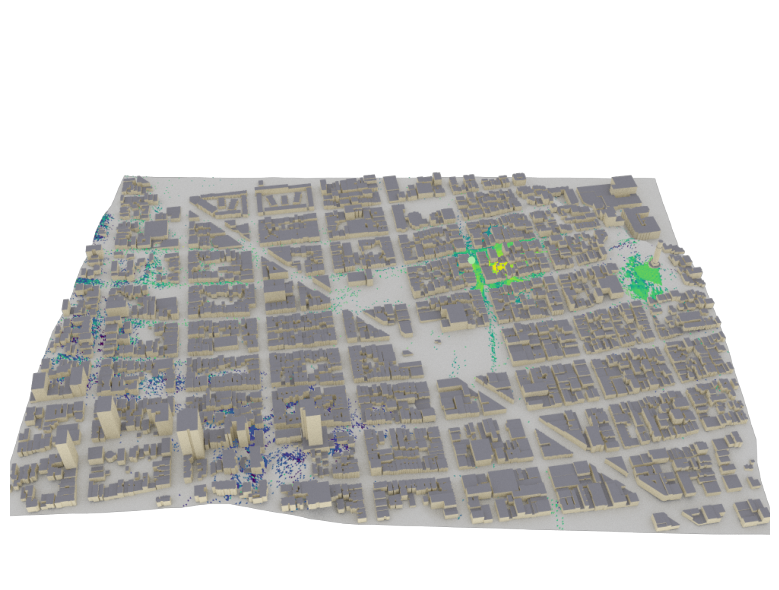

In [18]:
import inspect

def to_np(x): return x.detach().cpu().numpy() if hasattr(x, "detach") else np.array(x)

def call_filtered(fn, *args, **kw):
    """Call fn, dropping keyword arguments that this Sionna version does not know."""
    sig = inspect.signature(fn).parameters
    if not any(p.kind == p.VAR_KEYWORD for p in sig.values()):
        dropped = [k for k in kw if k not in sig]
        if dropped: print("  (ignored unknown arguments:", dropped, ")")
        kw = {k: v for k, v in kw.items() if k in sig}
    return fn(*args, **kw)

saved_tx_array = scene.tx_array
scene.tx_array = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5,
                             pattern="tr38901", polarization="V")              # BS element pattern for the map
bs_tx = Transmitter(name="bs_tx", position=scene.get("bs").position.numpy().reshape(-1).tolist())
scene.add(bs_tx); bs_tx.look_at(aim_point.tolist())

try:
    rm_solver = RadioMapSolver()
    rm_args = dict(samples_per_tx=2_000_000, max_depth=5, los=True, specular_reflection=True,
                   diffuse_reflection=False, refraction=True, diffraction=True)
    try:
        radio_map = call_filtered(rm_solver.__call__, scene, measurement_surface=measurement_surface, **rm_args)
        print("radio map computed")
    except Exception as e:
        print("measurement surface not usable (", repr(e)[:120], ") -> flat map plane at UE height")
        radio_map = call_filtered(rm_solver.__call__, scene, center=[float(center[0]), float(center[1]), float(np.median(outdoor_positions[:, 2]))],
                                  orientation=[0, 0, 0], size=[float(size[0]), float(size[1])], cell_size=(5.0, 5.0), **rm_args)
    try:
        pg = to_np(radio_map.path_gain); pg_db = 10 * np.log10(pg[pg > 0])
        vmin, vmax = float(np.percentile(pg_db, 2)), float(pg_db.max()); print(f"path gain range: {vmin:.0f} ... {vmax:.0f} dB")
    except Exception as e:
        vmin = vmax = None; print("could not read path gain:", e)

    def render_map(cam):
        kw = dict(camera=cam, radio_map=radio_map, resolution=(1000, 750), num_samples=128, show_devices=True)
        try:    return scene.render(rm_metric="path_gain", rm_db_scale=True, rm_vmin=vmin, rm_vmax=vmax, **kw)
        except TypeError: return scene.render(**kw)

    top_cam_rm = Camera(position=[float(center[0]), float(center[1]) - 1.0, 1100.0], look_at=[float(center[0]), float(center[1]), 0.0])
    render_map(top_cam_rm); render_map(auto_cam)
    try:
        radio_map.show(metric="path_gain"); plt.show()
    except Exception as e:
        print("radio_map.show() not available for this map type (", repr(e)[:80], ") - the renders above show the map.")
finally:
    scene.remove("bs_tx"); scene.tx_array = saved_tx_array        # always restore the single-antenna UE array

In [19]:

# Step 2 — Verify BS orientation and downtilt

import numpy as np

bs = scene.get("bs")

# Use the actual current BS position
bs_xyz = bs.position.numpy().reshape(-1)

# Aim at the selected outdoor target
bs.look_at(aim_point.tolist())

target_xyz = np.asarray(aim_point)

delta = target_xyz - bs_xyz

horizontal_distance = np.linalg.norm(delta[:2])

downtilt_deg = np.degrees(
    np.arctan2(-delta[2], horizontal_distance)
)

print("BS position:", bs_xyz)
print("Target:", target_xyz)
print("Horizontal distance:", horizontal_distance, "m")
print("Downtilt:", downtilt_deg, "degrees")
print("Sionna orientation:", bs.orientation)


BS position: [266.734  130.195   49.5552]
Target: [465.          95.          52.64714432]
Horizontal distance: 201.36556759140169 m
Downtilt: -0.879701119788278 degrees
Sionna orientation: [[-0.175684, -0.0153537, 0]]


In [20]:
# Export FINAL rotated UE region to Blender

import pandas as pd
from google.colab import files

# Verify that the data is consistent
assert len(outdoor_positions) == len(location_splits)
assert len(ue_dataset) == 3 * len(outdoor_positions)

rows = []

for location_id, position in enumerate(outdoor_positions):
    rows.append({
        "x": float(position[0]),
        "y": float(position[1]),
        "z": float(position[2]),
        "split": location_splits[location_id]
    })

df = pd.DataFrame(rows)

csv_filename = "ue_splits_465_95_rot10_FINAL.csv"
df.to_csv(csv_filename, index=False)

print("Exported locations:", len(df))
print(df["split"].value_counts())

assert len(df) == 236, "Check previous dataset cells"

files.download(csv_filename)




Exported locations: 236
split
train         131
test           49
validation     39
buffer         17
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 4 — Ray tracing and OFDM channels
`PathSolver` options (document in the report): LoS + specular reflection + diffraction, `max_depth = 4`; refraction and diffuse scattering off
(outdoor UEs, no scattering coefficients in the scene materials). `Paths.cir()` with `sampling_frequency = 1/T_sym`, `num_time_steps = 14`
gives the Doppler evolution over the slot, `cir_to_ofdm_channel()` is called on chunks of 24 UEs. The 4x4 array is traced once; M = 1 and 2 are sub-arrays.

In [21]:
# ---- numerology and helpers (numpy only) ----
import os, math, time, inspect, itertools
import numpy as np
import matplotlib.pyplot as plt

FC     = 3.5e9
C0     = 299_792_458.0
SCS    = 30e3
N_PRB  = 24
NSC    = 12 * N_PRB                 # 288 subcarriers
NSYM   = 14
T_SYM  = 0.5e-3 / NSYM              # mean OFDM symbol duration incl. CP (30 kHz SCS -> 0.5 ms slot)
T_SLOT = NSYM * T_SYM
SPEEDS = [3, 30, 120]               # km/h
FREQS  = (np.arange(NSC) - NSC / 2) * SCS            # baseband subcarrier frequencies
FD_NOM = {v: v / 3.6 * FC / C0 for v in SPEEDS}      # nominal max Doppler [Hz]
SNR_GRID = list(range(-5, 26, 5))                    # dB, used everywhere

print("max Doppler [Hz]:", {v: round(f, 1) for v, f in FD_NOM.items()})
print("Tc = 0.423/fD in OFDM symbols:", {v: round(0.423 / f / T_SYM, 1) for v, f in FD_NOM.items()})


def path_stats(p, tau, fd, dyn_db=30.0):
    """Per-UE multipath statistics.
    p, tau, fd : [n, P] path power, delay (first arrival = 0) and Doppler [Hz]; invalid paths have p == 0.
    Paths more than `dyn_db` below the strongest one are ignored."""
    pmax = p.max(1, keepdims=True)
    keep = (p > 0) & (p >= pmax * 10 ** (-dyn_db / 10))
    w = np.where(keep, p, 0.0)
    tot = np.maximum(w.sum(1), 1e-30)
    mom = lambda x, k: (w * np.where(keep, x, 0.0) ** k).sum(1) / tot
    t1, t2, t4 = mom(tau, 1), mom(tau, 2), mom(tau, 4)
    return dict(
        tau_rms=np.sqrt(np.maximum(t2 - t1 ** 2, 0)),          # RMS delay spread
        tau_max=np.where(keep, tau, 0).max(1),                 # max excess delay (within dyn_db)
        tau4=t4 ** 0.25,                                       # 4th-moment delay (interp. error predictor)
        fd2=mom(fd, 2) ** 0.5,                                 # RMS Doppler
        fd4=mom(fd, 4) ** 0.25,
        fd_max=np.where(keep, np.abs(fd), 0).max(1))


def subarray(H, M):
    """H: [n, 16, T, F] from the 4x4 trace -> M x M sub-array, re-normalised to unit mean power per UE.
    Element index = row*4+col, so the top-left 2x2 block is {0,1,4,5} for either ordering convention."""
    idx = {1: [0], 2: [0, 1, 4, 5], 4: list(range(16))}[M]
    Hs = H[:, idx]
    pw = (np.abs(Hs) ** 2).mean(axis=(1, 2, 3), keepdims=True)
    return (Hs / np.sqrt(np.maximum(pw, 1e-30))).astype(np.complex64)

max Doppler [Hz]: {3: 9.7, 30: 97.3, 120: 389.2}
Tc = 0.423/fD in OFDM symbols: {3: 1217.4, 30: 121.7, 120: 30.4}


In [22]:
# ---- plot style and helpers (used by every figure below) ----
import matplotlib as mpl
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 10.5, "axes.labelsize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "grid.linestyle": "-", "legend.frameon": False, "legend.fontsize": 9, "lines.markersize": 5})

EST_STYLE = {                                   # the same colour / marker for an estimator in EVERY figure
    "Perfect CSI":                 dict(color="#222222", ls=":",  marker=None, lw=1.6),
    "LS-nn":                       dict(color="#9e9e9e", ls=":",  marker="s",  lw=1.4),
    "LS-lin":                      dict(color="#6e6e6e", ls="--", marker="s",  lw=1.7),
    "LMMSE (site)":                dict(color="#1f77b4", ls="-",  marker="o",  lw=2.0),
    "LMMSE (site, 8-PRB window)":  dict(color="#7fb8e0", ls="-",  marker="o",  lw=1.6),
    "LMMSE (TDL)":                 dict(color="#9467bd", ls="-.", marker="^",  lw=1.8),
    "LMMSE (oracle cov.)":         dict(color="#444444", ls="-",  marker="x",  lw=1.2),
    "Ridge (learned linear)":      dict(color="#2ca02c", ls="-",  marker="D",  lw=2.0),
    "CNN (learned)":               dict(color="#d62728", ls="-",  marker="o",  lw=2.8),
}
def est_style(name): return dict(EST_STYLE.get(name, dict(color="tab:orange", ls="-", marker="o", lw=1.8)))

def layout(n):
    '''(rows, cols) with rows*cols == n whenever possible, so no panel is left empty.'''
    best = None
    for r in range(1, n + 1):
        if n % r == 0:
            c = n // r; score = abs(np.log((c / r) / 1.8)) + (0.6 if c > 6 else 0)
            if best is None or score < best[0]: best = (score, r, c)
    r, c = best[1], best[2]
    if r == 1 and c > 6: r, c = 2, int(np.ceil(n / 2))
    return r, c

def make_axes(n, w=3.9, h=3.1, **kw):
    r, c = layout(n)
    fig, axs = plt.subplots(r, c, figsize=(w * c, h * r), squeeze=False, constrained_layout=True, **kw)
    flat = list(axs.ravel())
    for ax in flat[n:]: fig.delaxes(ax)                 # never show an unused panel
    return fig, flat[:n], r, c

def shared_legend(fig, axes, ncol=None):
    seen = {}
    for ax in axes:
        for hnd, lab in zip(*ax.get_legend_handles_labels()): seen.setdefault(lab, hnd)
    if not seen: return
    ncol = ncol or min(len(seen), 5)
    try:    fig.legend(seen.values(), seen.keys(), loc="outside lower center", ncol=ncol)
    except Exception: fig.legend(seen.values(), seen.keys(), loc="lower center", ncol=ncol)

dB = lambda x: 10 * np.log10(np.maximum(x, 1e-12))

In [23]:
# [needs-sionna, needs-torch]
import torch
from sionna.rt import Transmitter, PathSolver
from sionna.phy.channel import cir_to_ofdm_channel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# Propagation mechanisms (document these in the report): LoS + specular reflection + diffraction, depth 4.
# Refraction (through-building) and diffuse scattering are off: UEs are outdoor and the scene materials have
# no scattering coefficients set.
SOLVER_OPTS = dict(max_depth=4, los=True, specular_reflection=True, diffuse_reflection=False,
                   refraction=False, diffraction=True, samples_per_src=500_000)
p_solver = PathSolver()

def trace(scene):
    """Call PathSolver, silently dropping kwargs your Sionna version does not know (CHECK printed list)."""
    sig = inspect.signature(PathSolver.__call__).parameters
    kw = {k: v for k, v in SOLVER_OPTS.items() if k in sig}
    dropped = [k for k in SOLVER_OPTS if k not in sig]
    if dropped: print("PathSolver does not accept:", dropped)
    return p_solver(scene, **kw)

_freqs_t = torch.as_tensor(FREQS, dtype=torch.float32, device=device)

def generate_channels(scene, pos, dirs, speed_kmh, bs_pos, chunk=24):
    """Uplink: UEs are transmitters (with velocity), the BS is the receiver -> no reverse_direction needed.
    Returns H [n, A, NSYM, NSC] (unit mean power per UE) and per-UE statistics."""
    Hs, st, los, gain, ok = [], {k: [] for k in ("tau_rms","tau_max","tau4","fd2","fd4","fd_max")}, [], [], []
    for s in range(0, len(pos), chunk):
        ids = list(range(s, min(s + chunk, len(pos))))
        for i in ids:
            scene.add(Transmitter(name=f"ue_{i}", position=[float(x) for x in pos[i]]))
            v = speed_kmh / 3.6 * np.array([np.cos(dirs[i]), np.sin(dirs[i]), 0.0])
            scene.get(f"ue_{i}").velocity = [float(x) for x in v]          # CHECK: velocity setter
        paths = trace(scene)
        a, tau = paths.cir(sampling_frequency=1 / T_SYM, num_time_steps=NSYM,
                           normalize_delays=False, out_type="torch")        # CHECK signature in 2.x
        a, tau = torch.as_tensor(a).to(device), torch.as_tensor(tau).to(device)
        assert tau.ndim == 3, "expected synthetic-array paths: tau [rx, tx, paths]"
        # a: [1, A, n_tx, 1, P, T]   tau: [1, n_tx, P]
        pw   = (a.abs() ** 2).mean(dim=(1, 5))[0, :, 0, :]                  # [n_tx, P]
        tau0 = tau[0]
        if tau0.shape[-1] == 0:                                   # the solver found no path for this whole chunk
            print(f"  WARNING: zero paths for UEs {ids[0]}..{ids[-1]} -> run diagnose_paths(scene, pos, bs_pos)")
            n_c = len(ids)
            Hs.append(np.zeros((n_c, scene.rx_array.num_ant, NSYM, NSC), np.complex64))
            for k in st: st[k].append(np.zeros(n_c))
            los.append(np.zeros(n_c, bool)); gain.append(np.full(n_c, -300.0)); ok.append(np.zeros(n_c, bool))
            for i in ids: scene.remove(f"ue_{i}")
            continue
        valid = (tau0 >= 0) & (pw > 0)
        tmin = torch.where(valid, tau0, torch.full_like(tau0, 1e9)).min(-1).values
        taun = torch.where(valid, tau0 - tmin[:, None], torch.zeros_like(tau0))
        ph = (a[..., 1:] * a[..., :-1].conj()).sum(dim=(1, 5))[0, :, 0, :]  # Doppler from phase slope
        fd = torch.angle(ph) / (2 * np.pi * T_SYM)
        a_b = a.permute(2, 0, 1, 3, 4, 5).unsqueeze(3)                      # [n_tx,1,A,1,1,P,T]
        h = cir_to_ofdm_channel(_freqs_t, a_b, taun[:, None, None, :], normalize=False)
        h = h[:, 0, :, 0, 0]                                                # [n_tx, A, T, NSC]
        pwr = (h.abs() ** 2).mean(dim=(1, 2, 3))
        h = h / torch.sqrt(pwr.clamp_min(1e-30)).view(-1, 1, 1, 1)
        stt = path_stats(pw.cpu().numpy(), taun.cpu().numpy(), fd.cpu().numpy())
        for k in st: st[k].append(stt[k])
        dist = np.linalg.norm(np.asarray(pos[ids]) - np.asarray(bs_pos)[None], axis=1)
        los.append(tmin.cpu().numpy() * C0 - dist < 0.1)                    # earliest path == geometric distance
        gain.append(10 * np.log10(pwr.cpu().numpy() + 1e-30))
        ok.append(valid.any(-1).cpu().numpy())
        Hs.append(h.cpu().numpy().astype(np.complex64))
        for i in ids: scene.remove(f"ue_{i}")
    out = {k: np.concatenate(v) for k, v in st.items()}
    out.update(H=np.concatenate(Hs), los=np.concatenate(los), gain_db=np.concatenate(gain), ok=np.concatenate(ok))
    return out


def generate_dataset(scene, positions, splits, loc_dirs, bs_pos, speeds=SPEEDS, k_aug=1, seed=1, chunk=24):
    """k = 0 : all non-buffer locations, the direction you already drew in Step 3.6 (same direction for every speed).
    k >= 1: extra random directions for TRAIN locations only (data augmentation for the learned estimators)."""
    rng = np.random.default_rng(seed)
    dirs = [loc_dirs] + [rng.uniform(0, 2 * np.pi, len(positions)) for _ in range(k_aug - 1)]
    cols = {}
    t0 = time.time()
    for k in range(k_aug):
        sel = np.where(splits != "buffer")[0] if k == 0 else np.where(splits == "train")[0]
        for v in speeds:
            r = generate_channels(scene, positions[sel], dirs[k][sel], v, bs_pos, chunk)
            keep = r["ok"]                                       # drop UEs with no propagation path
            n = int(keep.sum())
            if n == 0 and k == 0:
                raise RuntimeError("No UE has any propagation path. Run diagnose_paths(scene, positions, bs_pos) to find out why.")
            meta = dict(speed=np.full(n, v), loc=sel[keep], split=splits[sel][keep], dir_id=np.full(n, k),
                        pos=positions[sel][keep])
            for key, val in {**{kk: r[kk][keep] for kk in r if kk != "ok"}, **meta}.items():
                cols.setdefault(key, []).append(val)
            print(f"k={k} speed={v:>3} km/h: {n}/{len(sel)} UEs with paths   [{time.time()-t0:.0f}s]")
    return {k: np.concatenate(v) for k, v in cols.items()}

device: cuda


In [24]:
# [needs-sionna, needs-torch]  Run ray tracing ONCE with the 4x4 array (M = 1, 2 are sub-arrays of it).
K_AUG = 1          # set to 3-4 if the learned models overfit: extra random UE directions for TRAIN locations only
M_TRACE = 4

scene.rx_array = PlanarArray(num_rows=M_TRACE, num_cols=M_TRACE, vertical_spacing=0.5,
                             horizontal_spacing=0.5, pattern="tr38901", polarization="V")
bs = scene.get("bs")
bs_pos = bs.position.numpy().reshape(-1)

n_loc = len(outdoor_positions)
splits_arr = np.array([location_splits[i] for i in range(n_loc)])
loc_dirs   = np.array([ue_dataset[3 * i]["direction_rad"] for i in range(n_loc)])    # from Step 3.6

DS_FILE = "channel_dataset_4x4.pt"            # .pt file with channels + metadata (position, LoS flag, tau_rms, speed ...)
if os.path.exists(DS_FILE):
    ds = torch.load(DS_FILE, weights_only=False); print("loaded cached dataset", DS_FILE, "(delete the file to re-run the ray tracing)")
else:
    ds = generate_dataset(scene, outdoor_positions, splits_arr, loc_dirs, bs_pos, k_aug=K_AUG)
    torch.save(ds, DS_FILE)
print({k: v.shape for k, v in ds.items()})

k=0 speed=  3 km/h: 133/219 UEs with paths   [10s]
k=0 speed= 30 km/h: 133/219 UEs with paths   [15s]
k=0 speed=120 km/h: 133/219 UEs with paths   [20s]
{'tau_rms': (399,), 'tau_max': (399,), 'tau4': (399,), 'fd2': (399,), 'fd4': (399,), 'fd_max': (399,), 'H': (399, 16, 14, 288), 'los': (399,), 'gain_db': (399,), 'speed': (399,), 'loc': (399,), 'split': (399,), 'dir_id': (399,), 'pos': (399, 3)}


In [25]:
# [needs-sionna, needs-torch]  Diagnose "zero paths": run this if generate_dataset reports no paths.
def diagnose_paths(scene, pos, bs_pos, n=3):
    import mitsuba as mi
    print("tx_array elements:", scene.tx_array.num_ant, "| rx_array elements:", scene.rx_array.num_ant)
    print("receivers:", list(scene.receivers), "| transmitters:", list(scene.transmitters))
    bs_pos = np.asarray(bs_pos, float)
    # (1) is the BS embedded in / touching geometry?  cast short rays in 6 directions from the BS
    dirs = {"+x": (1, 0, 0), "-x": (-1, 0, 0), "+y": (0, 1, 0), "-y": (0, -1, 0), "+z": (0, 0, 1), "-z": (0, 0, -1)}
    for name, d in dirs.items():
        ray = mi.Ray3f(o=mi.Point3f(*[float(x) for x in bs_pos]), d=mi.Vector3f(*[float(x) for x in d]))
        ray.maxt = 3.0
        print(f"  surface within 3 m of the BS in {name}: {bool(np.asarray(scene.mi_scene.ray_test(ray)).item())}")
    # (2) straight line UE -> BS
    for i in range(n):
        p = np.asarray(pos[i], float); dist = np.linalg.norm(bs_pos - p)
        ray = mi.Ray3f(o=mi.Point3f(*[float(x) for x in p]), d=mi.Vector3f(*[float(x) for x in (bs_pos - p) / dist]))
        ray.maxt = float(dist - 2.0)
        print(f"  UE {i}: distance {dist:.0f} m, line of sight to 2 m before the BS: {not bool(np.asarray(scene.mi_scene.ray_test(ray)).item())}")
    # (3) trace a few UEs with different mechanisms and report the number of paths found
    for i in range(n): scene.add(Transmitter(name=f"dbg_{i}", position=[float(x) for x in pos[i]]))
    base = dict(SOLVER_OPTS)
    trials = {"LoS only": dict(max_depth=1, los=True, specular_reflection=False, diffraction=False, refraction=False),
              "current options": base,
              "+ refraction": {**base, "refraction": True},
              "+ diffuse reflection": {**base, "diffuse_reflection": True}}
    for label, opts in trials.items():
        try:
            sig = inspect.signature(PathSolver.__call__).parameters
            kw = {k: v for k, v in opts.items() if k in sig}
            print(f"  [{label}] accepted kwargs: {sorted(kw)}")
            paths = p_solver(scene, **kw)
            a, tau = paths.cir(sampling_frequency=1 / T_SYM, num_time_steps=1, normalize_delays=False, out_type="torch")
            print(f"  [{label}] a {tuple(a.shape)}  tau {tuple(torch.as_tensor(tau).shape)}  valid paths per UE: "
                  f"{(torch.as_tensor(tau)[0] >= 0).sum(-1).tolist() if torch.as_tensor(tau).ndim == 3 else 'n/a'}")
        except Exception as e:
            print(f"  [{label}] failed: {e!r}")
    for i in range(n): scene.remove(f"dbg_{i}")

# diagnose_paths(scene, outdoor_positions, bs.position.numpy().reshape(-1))      # run only if no UE has a path

jit_flush_malloc_cache(): Dr.Jit exhausted the available memory and had to flush its allocation cache to free up additional memory. This is an expensive operation and will have a negative effect on performance. You may want to change your computation so that it uses less memory. This warning will only be displayed once.


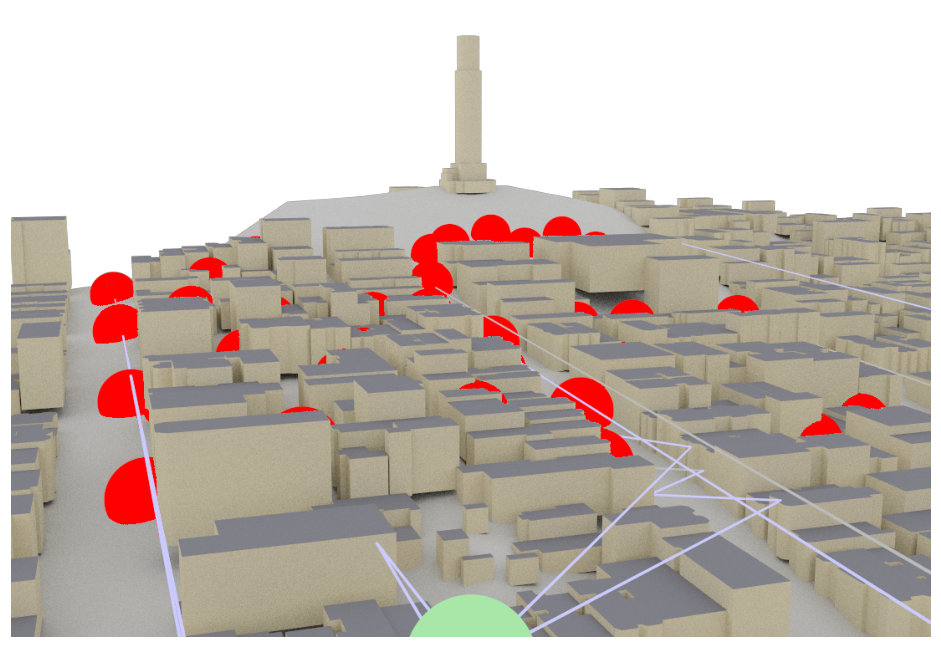

In [26]:
# 3D picture of my BS and UE grid with their paths
import numpy as np
from sionna.rt import Camera

UE_STEP  = 6          # use every 6th grid point (~40 UEs). Smaller = more paths but more GPU memory
MAX_DEPTH = 3         # 3 keeps the picture readable (your example used 5)

pos = np.asarray(outdoor_positions)[::UE_STEP]
bs_p = scene.get("bs").position.numpy().reshape(-1)
grid_c = np.asarray(outdoor_positions).mean(0)

for _n in list(scene.transmitters): scene.remove(_n)
for i, p in enumerate(pos):
    scene.add(Transmitter(name=f"viz_{i}", position=[float(x) for x in p]))
scene.rx_array = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5,
                             pattern="tr38901", polarization="V")      # 1 element, so one line per path

paths = p_solver(scene=scene, max_depth=MAX_DEPTH, los=True, specular_reflection=True,
                 diffuse_reflection=False, refraction=False, synthetic_array=False,
                 samples_per_src=100_000, seed=41)

# camera: behind and above the BS, looking at the centre of the UE grid
h = (bs_p - grid_c) * np.array([1, 1, 0]); h = h / (np.linalg.norm(h) + 1e-9)
cam = Camera(position=(bs_p + h * 120 + np.array([0, 0, 60])).tolist(), look_at=grid_c.tolist())
scene.render(camera=cam, paths=paths, show_devices=True, resolution=(1100, 750), num_samples=128)
plt.show()

for _n in list(scene.transmitters): scene.remove(_n)                    # clean up
scene.rx_array = PlanarArray(num_rows=4, num_cols=4, vertical_spacing=0.5, horizontal_spacing=0.5,
                             pattern="tr38901", polarization="V")       # restore the 4x4 array

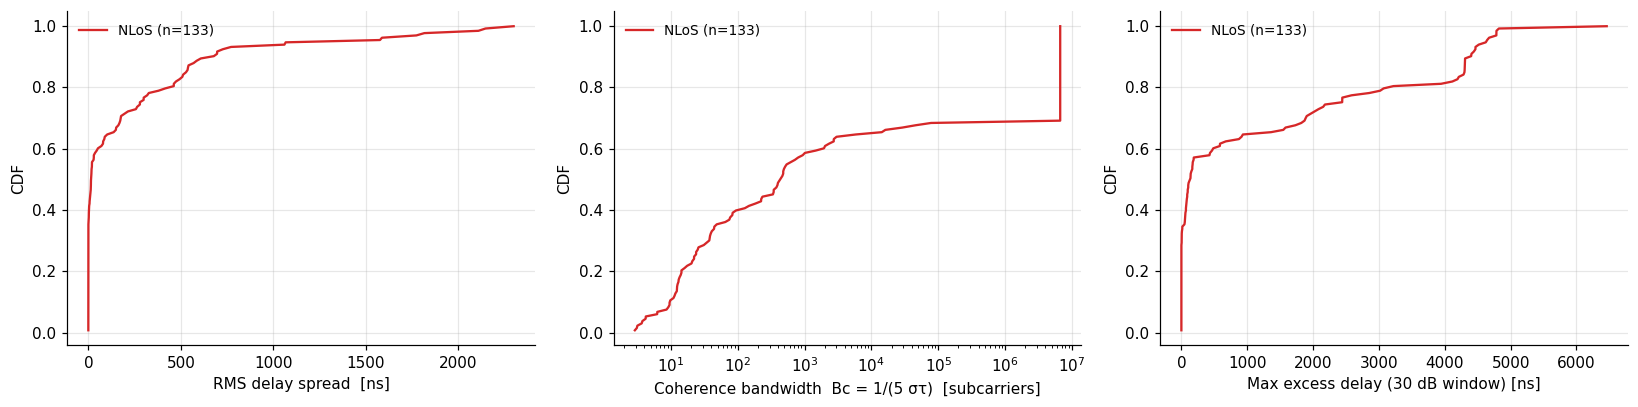

LoS fraction: 0.00
NLoS : median στ=  15.1 ns | median Bc= 440.4 sc | 90th pct τmax= 4381.6 ns

Time selectivity (nominal):
    3 km/h: fD=   9.7 Hz | Tc=0.423/fD=  43.48 ms =  1217.4 OFDM symbols | phase drift over a slot =  0.03 rad
   30 km/h: fD=  97.3 Hz | Tc=0.423/fD=   4.35 ms =   121.7 OFDM symbols | phase drift over a slot =  0.31 rad
  120 km/h: fD= 389.2 Hz | Tc=0.423/fD=   1.09 ms =    30.4 OFDM symbols | phase drift over a slot =  1.22 rad
  measured max |Doppler| over UEs @ 3 km/h: 9.7 Hz (95th pct)
  measured max |Doppler| over UEs @ 30 km/h: 97.2 Hz (95th pct)
  measured max |Doppler| over UEs @ 120 km/h: 388.7 Hz (95th pct)


In [27]:
# ---- Channel statistics (numpy only) ----
def coherence(ds):
    sel = (ds["speed"] == SPEEDS[0]) & (ds["dir_id"] == 0)      # delay statistics do not depend on speed
    tau_rms, tau_max, los = ds["tau_rms"][sel], ds["tau_max"][sel], ds["los"][sel]
    Bc = 1 / (5 * np.maximum(tau_rms, 1e-12))            # Hz
    return tau_rms, tau_max, Bc / SCS, los

def cdf(ax, x, label, **kw):
    x = np.sort(x); ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=f"{label} (n={len(x)})", **kw)

def plot_stats(ds):
    tau_rms, tau_max, Bc_sc, los = coherence(ds)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for m, lab, c in ((los, "LoS", "tab:blue"), (~los, "NLoS", "tab:red")):
        if m.sum() == 0: continue
        cdf(ax[0], tau_rms[m] * 1e9, lab, color=c); cdf(ax[1], Bc_sc[m], lab, color=c); cdf(ax[2], tau_max[m] * 1e9, lab, color=c)
    ax[0].set_xlabel("RMS delay spread  [ns]"); ax[1].set_xlabel("Coherence bandwidth  Bc = 1/(5 στ)  [subcarriers]")
    ax[2].set_xlabel("Max excess delay (30 dB window) [ns]"); ax[1].set_xscale("log")
    for a_ in ax: a_.set_ylabel("CDF"); a_.grid(alpha=.3); a_.legend()
    plt.tight_layout(); plt.show()
    print(f"LoS fraction: {los.mean():.2f}")
    for m, lab in ((los, "LoS"), (~los, "NLoS")):
        if m.sum():
            print(f"{lab:5s}: median στ={np.median(tau_rms[m])*1e9:6.1f} ns | median Bc={np.median(Bc_sc[m]):6.1f} sc "
                  f"| 90th pct τmax={np.percentile(tau_max[m],90)*1e9:7.1f} ns")
    print("\nTime selectivity (nominal):")
    for v in SPEEDS:
        fd = FD_NOM[v]; print(f"  {v:>3} km/h: fD={fd:6.1f} Hz | Tc=0.423/fD={0.423/fd*1e3:7.2f} ms = {0.423/fd/T_SYM:7.1f} OFDM symbols"
                              f" | phase drift over a slot = {2*np.pi*fd*T_SLOT:5.2f} rad")
    for v in SPEEDS:
        s = ds["speed"] == v
        print(f"  measured max |Doppler| over UEs @ {v} km/h: {np.percentile(ds['fd_max'][s], 95):.1f} Hz (95th pct)")

plot_stats(ds)

## Step 5 — Pilot configurations, overhead and predictions
NR DMRS: `additional_position` 0-3, `config_type` 1 and 2, `num_cdm_groups_without_data` 1 and 2 (reserved REs count in the overhead).
Custom sparse patterns below the NR minimum: a comb on every 4th subcarrier of one symbol and a comb on every 16th subcarrier of two symbols.
The prediction compares the pilot spacing with the 2-D sampling requirement `Δf·Δf_sc·τ_max <= 1` and `Δt·T_sym·2f_D <= 1`.

In [28]:
import pandas as pd

WIN = 96                                   # sub-band (8 PRBs) used by the windowed estimators / learned filters

def dmrs_symbols(add_pos, l0=2):          # PUSCH mapping type A, 14 symbols (TS 38.211, Table 6.4.1.1.3-3)
    return {0: [l0], 1: [l0, 11], 2: [l0, 7, 11], 3: [l0, 5, 8, 11]}[add_pos]

def make_cfg(name, sym_idx, pil_sc, res_sc, kind):
    Tp, Fp = np.array(sorted(sym_idx)), np.where(pil_sc)[0]
    pilot = np.zeros((NSYM, NSC), bool); pilot[np.ix_(Tp, Fp)] = True
    reserved = np.zeros((NSYM, NSC), bool); reserved[np.ix_(Tp, np.where(res_sc)[0])] = True
    gap_t = np.diff(Tp).max() if len(Tp) > 1 else 0
    edge = max(Tp[0], NSYM - 1 - Tp[-1])
    return dict(name=name, kind=kind, Tp=Tp, Fp=Fp, Fp_w=Fp[Fp < WIN], pilot=pilot, reserved=reserved,
                n_pilot=int(pilot.sum()), n_reserved=int(reserved.sum()), n_data=int((~reserved).sum()),
                eta=reserved.sum() / (NSYM * NSC), df_max=int(np.diff(Fp).max()), df_mean=NSC / len(Fp),
                dt_eff=int(max(gap_t, 2 * edge)), n_psym=len(Tp))

def nr_cfg(ctype, add_pos, ncdm):
    k = np.arange(NSC)
    if ctype == 1:
        pil = k % 2 == 0;  res = pil if ncdm == 1 else np.ones(NSC, bool)
    else:
        pil = (k % 6) < 2; res = {1: (k % 6) < 2, 2: (k % 6) < 4, 3: np.ones(NSC, bool)}[ncdm]
    return make_cfg(f"NR-T{ctype}-p{add_pos}" + (f"-cdm{ncdm}" if ncdm > 1 else ""), dmrs_symbols(add_pos), pil, res, "NR")

def comb_cfg(spacing, syms):
    pil = (np.arange(NSC) % spacing) == 0
    return make_cfg(f"comb{spacing}-{len(syms)}sym", syms, pil, pil, "custom")

CONFIGS = [nr_cfg(1, 3, 1), nr_cfg(1, 2, 1), nr_cfg(1, 1, 2), nr_cfg(1, 1, 1), nr_cfg(1, 0, 1),
           nr_cfg(2, 1, 2), nr_cfg(2, 1, 1), nr_cfg(2, 0, 1),
           comb_cfg(4, [2]), comb_cfg(16, [2, 11])]       # 2 custom combs below the NR minimum: moderately sparse and very sparse
CFG = {c["name"]: c for c in CONFIGS}
for c in CONFIGS:                                    # the estimators below assume pilots = Tp x Fp (separable)
    assert c["pilot"].sum() == len(c["Tp"]) * len(c["Fp"])
    assert (np.diff(c["Fp"][c["Fp"] < 96]) == np.diff(c["Fp"][(c["Fp"] >= 96) & (c["Fp"] < 192)])).all()

tab = pd.DataFrame([dict(config=c["name"], pilot_syms=c["n_psym"], pilot_REs=c["n_pilot"], reserved_REs=c["n_reserved"],
                         **{"Δf_max[sc]": c["df_max"], "Δf_mean[sc]": round(c["df_mean"], 1), "Δt_eff[sym]": c["dt_eff"]},
                         **{"η [%]": round(100 * c["eta"], 2)}) for c in CONFIGS]).sort_values("η [%]", ascending=False)
print(tab.to_string(index=False))

       config  pilot_syms  pilot_REs  reserved_REs  Δf_max[sc]  Δf_mean[sc]  Δt_eff[sym]  η [%]
     NR-T1-p3           4        576           576           2          2.0            4  14.29
NR-T1-p1-cdm2           2        288           576           2          2.0            9  14.29
     NR-T1-p2           3        432           432           2          2.0            5  10.71
NR-T2-p1-cdm2           2        192           384           5          3.0            9   9.52
     NR-T1-p1           2        288           288           2          2.0            9   7.14
     NR-T2-p1           2        192           192           5          3.0            9   4.76
     NR-T1-p0           1        144           144           2          2.0           22   3.57
     NR-T2-p0           1         96            96           5          3.0           22   2.38
   comb4-1sym           1         72            72           4          4.0           22   1.79
  comb16-2sym           2         36    

In [29]:
# [needs-sionna] OPTIONAL cross-check: your NR masks vs. Sionna's PUSCH pilot pattern (CHECK attribute names in 2.x)
try:
    from sionna.phy.nr import PUSCHConfig, PUSCHTransmitter
    for (ct, ap, nc) in [(1, 1, 1), (1, 1, 2), (2, 1, 1)]:
        pc = PUSCHConfig()
        pc.carrier.subcarrier_spacing = 30; pc.carrier.n_size_grid = N_PRB
        pc.dmrs.config_type = ct; pc.dmrs.additional_position = ap; pc.dmrs.num_cdm_groups_without_data = nc
        mask = np.asarray(PUSCHTransmitter(pc).resource_grid.pilot_pattern.mask)[0, 0].astype(bool)
        mine = nr_cfg(ct, ap, nc)["reserved"]
        print((ct, ap, nc), "mask identical to Sionna:", bool((mask == mine).all()))
except Exception as e:
    print("Cross-check skipped:", repr(e))

Cross-check skipped: TypeError("can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.")


In [30]:
FAIL_DB = -15.0
def predict(cfg, d):
    v = int(d["speed"][0]); fD = FD_NOM[v]
    nyq_f = cfg["df_max"] * SCS * d["tau_max"] <= 1
    nyq_t = np.full(nyq_f.shape, cfg["dt_eff"] * T_SYM * 2 * fD <= 1)      # depends on speed only
    nf = (2 * np.pi * cfg["df_max"] * SCS * d["tau4"]) ** 4 / 120
    if cfg["n_psym"] > 1:
        nt = (2 * np.pi * d["fd4"] * cfg["dt_eff"] * T_SYM) ** 4 / 120
    else:
        dist = np.arange(NSYM) - cfg["Tp"][0]
        nt = (2 * np.pi * d["fd2"] * T_SYM) ** 2 * np.mean(dist ** 2)
    nmse = np.minimum(nf + nt, 2.0)
    return nyq_f, nyq_t, nmse

def prediction_table(ds, split="test"):
    rows = []
    for c in CONFIGS:
        row = {"config": c["name"], "η[%]": round(100 * c["eta"], 2)}
        for v in SPEEDS:
            sel = (ds["split"] == split) & (ds["speed"] == v) & (ds["dir_id"] == 0)
            d = {k: ds[k][sel] for k in ("speed", "tau_max", "tau4", "fd2", "fd4")}
            nf, nt, nm = predict(c, d)
            med = 10 * np.log10(np.median(nm))
            row[f"{v}km/h: Nyq-f fail%"] = round(100 * (1 - nf.mean()))
            row[f"{v}km/h: Nyq-t fail%"] = round(100 * (1 - nt.mean()))
            row[f"{v}km/h: pred. NMSE_lin[dB]"] = round(med, 1)
            row[f"{v}km/h: verdict"] = "FAIL" if med > FAIL_DB else "ok"
        rows.append(row)
    return pd.DataFrame(rows)

PRED = prediction_table(ds)
print(PRED.to_string(index=False))

       config  η[%]  3km/h: Nyq-f fail%  3km/h: Nyq-t fail%  3km/h: pred. NMSE_lin[dB] 3km/h: verdict  30km/h: Nyq-f fail%  30km/h: Nyq-t fail%  30km/h: pred. NMSE_lin[dB] 30km/h: verdict  120km/h: Nyq-f fail%  120km/h: Nyq-t fail%  120km/h: pred. NMSE_lin[dB] 120km/h: verdict
     NR-T1-p3 14.29                   0                   0                      -81.1             ok                    0                    0                       -63.7              ok                     0                     0                        -40.9               ok
     NR-T1-p2 10.71                   0                   0                      -81.0             ok                    0                    0                       -59.9              ok                     0                     0                        -37.2               ok
NR-T1-p1-cdm2 14.29                   0                   0                      -80.5             ok                    0                    0                       

## Step 6 — Classical estimators
LS + nearest-neighbour (`LS-nn`), LS + linear interpolation (`LS-lin`), LMMSE with time and frequency covariances estimated on the **training region**
(`site`, separable Kronecker form, optionally per 8-PRB window), LMMSE with generic 3GPP TDL-C statistics (`TDL`), an oracle covariance from the test region, and perfect CSI
(NMSE = 0). All estimators are applied per receive antenna.

In [31]:
# ---- data views ----
M_EVAL = 4                                   # 1, 2 or 4 (sub-arrays of the 4x4 trace)

def view(ds, M, split, speed=None, base_only=False):
    sel = ds["split"] == split
    if speed is not None: sel &= ds["speed"] == speed
    if base_only: sel &= ds["dir_id"] == 0
    return subarray(ds["H"][sel], M), ds["speed"][sel]

def pilots_of(H, cfg):
    return H[:, :, cfg["Tp"]][:, :, :, cfg["Fp"]]

def noise_like(shape, sig2, rng):
    return ((rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) * np.sqrt(sig2 / 2)).astype(np.complex64)

# ---- LS + interpolation ----
_I = {}
def interp_mats(cfg, kind):
    key = (cfg["name"], kind)
    if key not in _I:
        def mat(nodes, n):
            A = np.zeros((n, len(nodes))); x = np.arange(n)
            for j in range(len(nodes)):
                if kind == "nn":
                    A[:, j] = 0
                else:
                    e = np.zeros(len(nodes)); e[j] = 1; A[:, j] = np.interp(x, nodes, e)   # linear, edge hold
            if kind == "nn":
                A[x, np.argmin(np.abs(x[:, None] - nodes[None]), axis=1)] = 1
            return A.astype(np.float32)
        _I[key] = (mat(cfg["Tp"], NSYM), mat(cfg["Fp"], NSC))
    return _I[key]

def est_ls(Hp, cfg, kind):
    At, Af = interp_mats(cfg, kind)
    return np.einsum("tp,...pf,kf->...tk", At, Hp, Af, optimize=True)

# ---- covariances from data ----
def toeplitzify(R):
    """WSSUS (paper Eq. 20): the correlation depends only on the lag. Average along the diagonals (a few hundred free
    numbers instead of n^2 estimated from ~100 independent UEs), then project to the PSD cone. This removes the
    over-fitting that made the full-band sample covariance worse than its own 8-PRB sub-block."""
    n = R.shape[0]; out = np.zeros_like(R)
    for k in range(-(n - 1), n):
        idx = np.arange(max(0, -k), min(n, n - k))
        out[idx, idx + k] = np.mean(np.diagonal(R, offset=k))
    w, U = np.linalg.eigh((out + out.conj().T) / 2)
    out = (U * np.maximum(w, 0)) @ U.conj().T
    return out / np.real(np.trace(out)) * n

def estimate_cov(H, stationary=True):
    """H [n, A, T, F]  ->  R_f [F,F], R_t [T,T] (unit mean diagonal)."""
    n, A, T, F = H.shape
    Hf = H.reshape(-1, F)
    Rf = (Hf.T @ Hf.conj()) / Hf.shape[0]
    Ht = H.transpose(0, 1, 3, 2).reshape(-1, T)
    Rt = (Ht.T @ Ht.conj()) / Ht.shape[0]
    Rf = Rf / np.real(np.trace(Rf)) * F; Rt = Rt / np.real(np.trace(Rt)) * T
    if stationary: Rf, Rt = toeplitzify(Rf), toeplitzify(Rt)
    return Rf.astype(np.complex128), Rt.astype(np.complex128)

class SepLMMSE:
    """LMMSE with R = R_t (x) R_f. y: [..., Tp, Fp] LS estimates -> [..., NSYM, F]."""
    def __init__(self, Rf, Rt, Tp, Fp):
        lt, Ut = np.linalg.eigh(Rt[np.ix_(Tp, Tp)]); lf, Uf = np.linalg.eigh(Rf[np.ix_(Fp, Fp)])
        self.lt, self.lf = np.maximum(lt, 0), np.maximum(lf, 0)
        self.Ut, self.Uf = Ut.astype(np.complex64), Uf.astype(np.complex64)
        self.Gt, self.Gf = Rt[:, Tp].astype(np.complex64), Rf[:, Fp].astype(np.complex64)
    def __call__(self, y, sig2):
        C = self.Ut.conj().T @ y @ self.Uf.conj()
        C = C / (self.lt[:, None] * self.lf[None, :] + sig2).astype(np.float32)
        return self.Gt @ (self.Ut @ C @ self.Uf.T) @ self.Gf.T

def run_windowed(fn_rows, Hp, cfg):
    """Apply a per-window function [R,Tp,Fpw] -> [R,NSYM,WIN] on the nw = NSC/WIN windows of the band."""
    Tp, Fpw, nw = cfg["Tp"], cfg["Fp_w"], NSC // WIN
    lead = Hp.shape[:-2]
    Hw = np.moveaxis(Hp.reshape(*lead, len(Tp), nw, len(Fpw)), -2, -3).reshape(-1, len(Tp), len(Fpw))
    out = fn_rows(Hw).reshape(*lead, nw, NSYM, WIN)
    return np.moveaxis(out, -3, -2).reshape(*lead, NSYM, NSC)

# ---- generic 3GPP TDL covariance (what a receiver without site knowledge would use) ----
def tdl_covs(model="C", delay_spread=300e-9):
    try:
        from sionna.phy.channel import tdl_freq_cov_mat, tdl_time_cov_mat
        toN = lambda x: np.asarray(x.detach().cpu().numpy() if hasattr(x, "detach") else x)
        Rf = toN(tdl_freq_cov_mat(model, SCS, NSC, delay_spread))
        Rt = {v: toN(tdl_time_cov_mat(model, v / 3.6, FC, T_SYM, NSYM)) for v in SPEEDS}
        src = f"Sionna TDL-{model}, DS={delay_spread*1e9:.0f} ns"
    except Exception as e:                       # analytic fallback: exponential PDP + Jakes
        from scipy.special import j0
        d = np.arange(NSC)[:, None] - np.arange(NSC)[None]
        Rf = 1 / (1 + 1j * 2 * np.pi * d * SCS * delay_spread)
        dt = np.arange(NSYM)[:, None] - np.arange(NSYM)[None]
        Rt = {v: j0(2 * np.pi * FD_NOM[v] * dt * T_SYM).astype(complex) for v in SPEEDS}
        src = f"analytic fallback (exp. PDP DS={delay_spread*1e9:.0f} ns + Jakes) because: {e!r}"
    print("generic covariance:", src)
    return Rf.astype(np.complex128), {v: r.astype(np.complex128) for v, r in Rt.items()}

In [32]:
# ---- build covariances: site-specific (train region), oracle (test region), generic TDL ----
Htr, vtr = view(ds, M_EVAL, "train")
Hte_v = {v: view(ds, M_EVAL, "test", v, base_only=True)[0] for v in SPEEDS}
Hva_v = {v: view(ds, M_EVAL, "validation", v, base_only=True)[0] for v in SPEEDS}
print("train samples", Htr.shape, "| test per speed", {v: h.shape[0] for v, h in Hte_v.items()})

Rf_site, _ = estimate_cov(Htr)
Rt_site = {v: estimate_cov(Htr[vtr == v])[1] for v in SPEEDS}
Hte_all = np.concatenate([Hte_v[v] for v in SPEEDS])
Rf_orac, _ = estimate_cov(Hte_all)
Rt_orac = {v: estimate_cov(Hte_v[v])[1] for v in SPEEDS}
Rf_tdl, Rt_tdl = tdl_covs("C", 300e-9)

COVS = {"site": (Rf_site, Rt_site), "oracle": (Rf_orac, Rt_orac), "tdl": (Rf_tdl, Rt_tdl)}
_L = {}
def lmmse(tag, cfg, v, windowed=False, Rt_from=None):
    """Rt_from: use the time covariance of another speed (mismatch experiments)."""
    Rf, Rt = COVS[tag]; Rt = Rt[Rt_from if Rt_from is not None else v]
    key = (tag, cfg["name"], v, windowed, Rt_from)
    if key not in _L:
        _L[key] = (SepLMMSE(Rf[:WIN, :WIN], Rt, cfg["Tp"], cfg["Fp_w"]) if windowed
                   else SepLMMSE(Rf, Rt, cfg["Tp"], cfg["Fp"]))
    f = _L[key]
    if windowed: return lambda Hp, s2: run_windowed(lambda Y: f(Y, s2), Hp, cfg)
    return lambda Hp, s2: f(Hp, s2)

train samples (216, 16, 14, 288) | test per speed {3: 39, 30: 39, 120: 39}
generic covariance: analytic fallback (exp. PDP DS=300 ns + Jakes) because: ImportError("cannot import name 'tdl_freq_cov_mat' from 'sionna.phy.channel' (/usr/local/lib/python3.13/dist-packages/sionna/phy/channel/__init__.py)")


In [33]:
# ---- sanity checks for the Kronecker LMMSE and the interpolators (cheap, run once) ----
_c = CFG["NR-T1-p1"]; _rng = np.random.default_rng(0)
_y = noise_like((2, 3, len(_c["Tp"]), len(_c["Fp"])), 1.0, _rng)
_f = SepLMMSE(Rf_site[:WIN, :WIN], Rt_site[3], _c["Tp"], _c["Fp_w"])
_Y = noise_like((2, len(_c["Tp"]), len(_c["Fp_w"])), 1.0, _rng); _s2 = 0.1
_Rpp = np.kron(Rt_site[3][np.ix_(_c["Tp"], _c["Tp"])], Rf_site[:WIN, :WIN][np.ix_(_c["Fp_w"], _c["Fp_w"])])
_Rhp = np.kron(Rt_site[3][:, _c["Tp"]], Rf_site[:WIN, :WIN][:, _c["Fp_w"]])
_ref = (_Rhp @ np.linalg.solve(_Rpp + _s2 * np.eye(_Rpp.shape[0]), _Y.reshape(2, -1).T)).T.reshape(2, NSYM, WIN)
print("Kronecker LMMSE vs brute-force  max abs err:", np.abs(_f(_Y, _s2) - _ref).max())
_h = np.exp(2j * np.pi * 0.01 * np.arange(NSC))[None, None, None, :] * np.ones((1, 1, NSYM, 1))
print("LS-lin reproduces a slow tone, NMSE:",
      np.mean(np.abs(est_ls(pilots_of(_h, _c), _c, "lin") - _h) ** 2) / np.mean(np.abs(_h) ** 2))

Kronecker LMMSE vs brute-force  max abs err: 2.53089949020265e-05
LS-lin reproduces a slow tone, NMSE: 1.5636632273530445e-05


In [34]:
# ---- NMSE vs SNR for every config / speed / estimator ----
NMSE = {}                                           # (cfg, speed, estimator) -> array over SNR_GRID

def nmse_curve(H, cfg, fn, snrs=SNR_GRID, reps=2, seed=0):
    rng = np.random.default_rng(seed)
    Hp = pilots_of(H, cfg); den = (np.abs(H) ** 2).sum(); out = np.zeros(len(snrs))
    for i, snr in enumerate(snrs):
        s2 = 10 ** (-snr / 10)
        for _ in range(reps):
            out[i] += (np.abs(H - fn(Hp + noise_like(Hp.shape, s2, rng), s2)) ** 2).sum()
    return out / (reps * den)

def classical(cfg, v):
    return {"LS-nn": lambda Hp, s2: est_ls(Hp, cfg, "nn"),
            "LS-lin": lambda Hp, s2: est_ls(Hp, cfg, "lin"),
            "LMMSE (site)": lmmse("site", cfg, v),
            "LMMSE (site, 8-PRB window)": lmmse("site", cfg, v, windowed=True),
            "LMMSE (TDL)": lmmse("tdl", cfg, v),
            "LMMSE (oracle cov.)": lmmse("oracle", cfg, v)}

def run_classical(cfgs=CONFIGS, data=Hte_v, store=NMSE, tag=""):
    t0 = time.time()
    for c in cfgs:
        for v in SPEEDS:
            for name, fn in classical(c, v).items():
                store[(c["name"], v, name + tag)] = nmse_curve(data[v], c, fn)
        print(f"{c['name']:16s} done  [{time.time()-t0:.0f}s]")

run_classical()

NR-T1-p3         done  [42s]
NR-T1-p2         done  [75s]
NR-T1-p1-cdm2    done  [104s]
NR-T1-p1         done  [131s]
NR-T1-p0         done  [151s]
NR-T2-p1-cdm2    done  [174s]
NR-T2-p1         done  [194s]
NR-T2-p0         done  [214s]
comb4-1sym       done  [229s]
comb16-2sym      done  [241s]


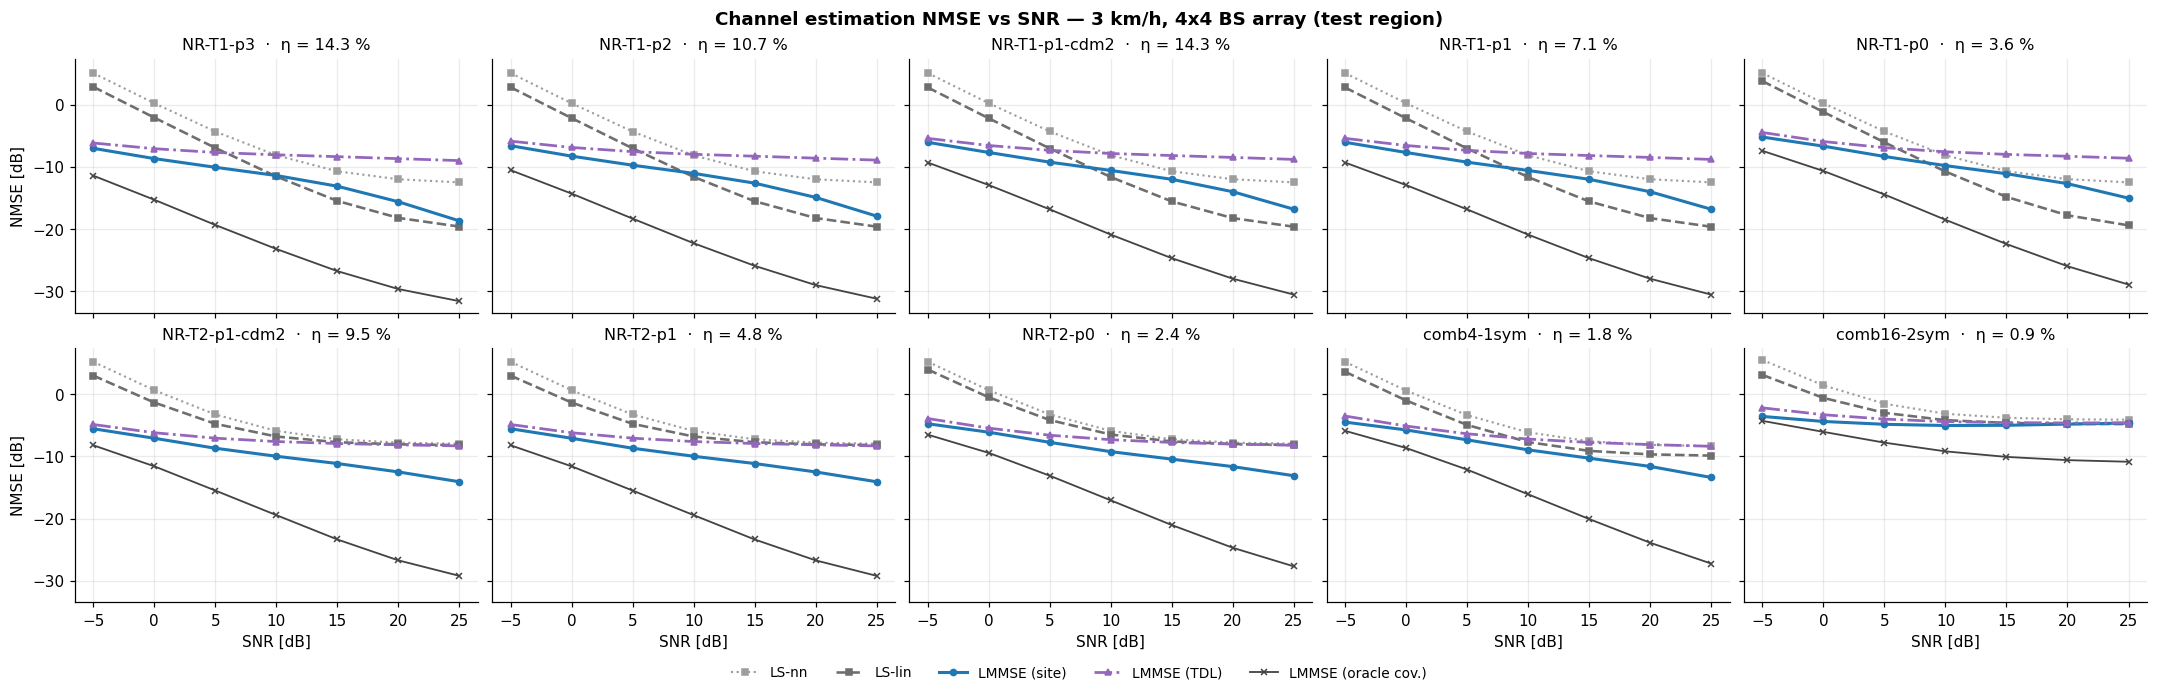

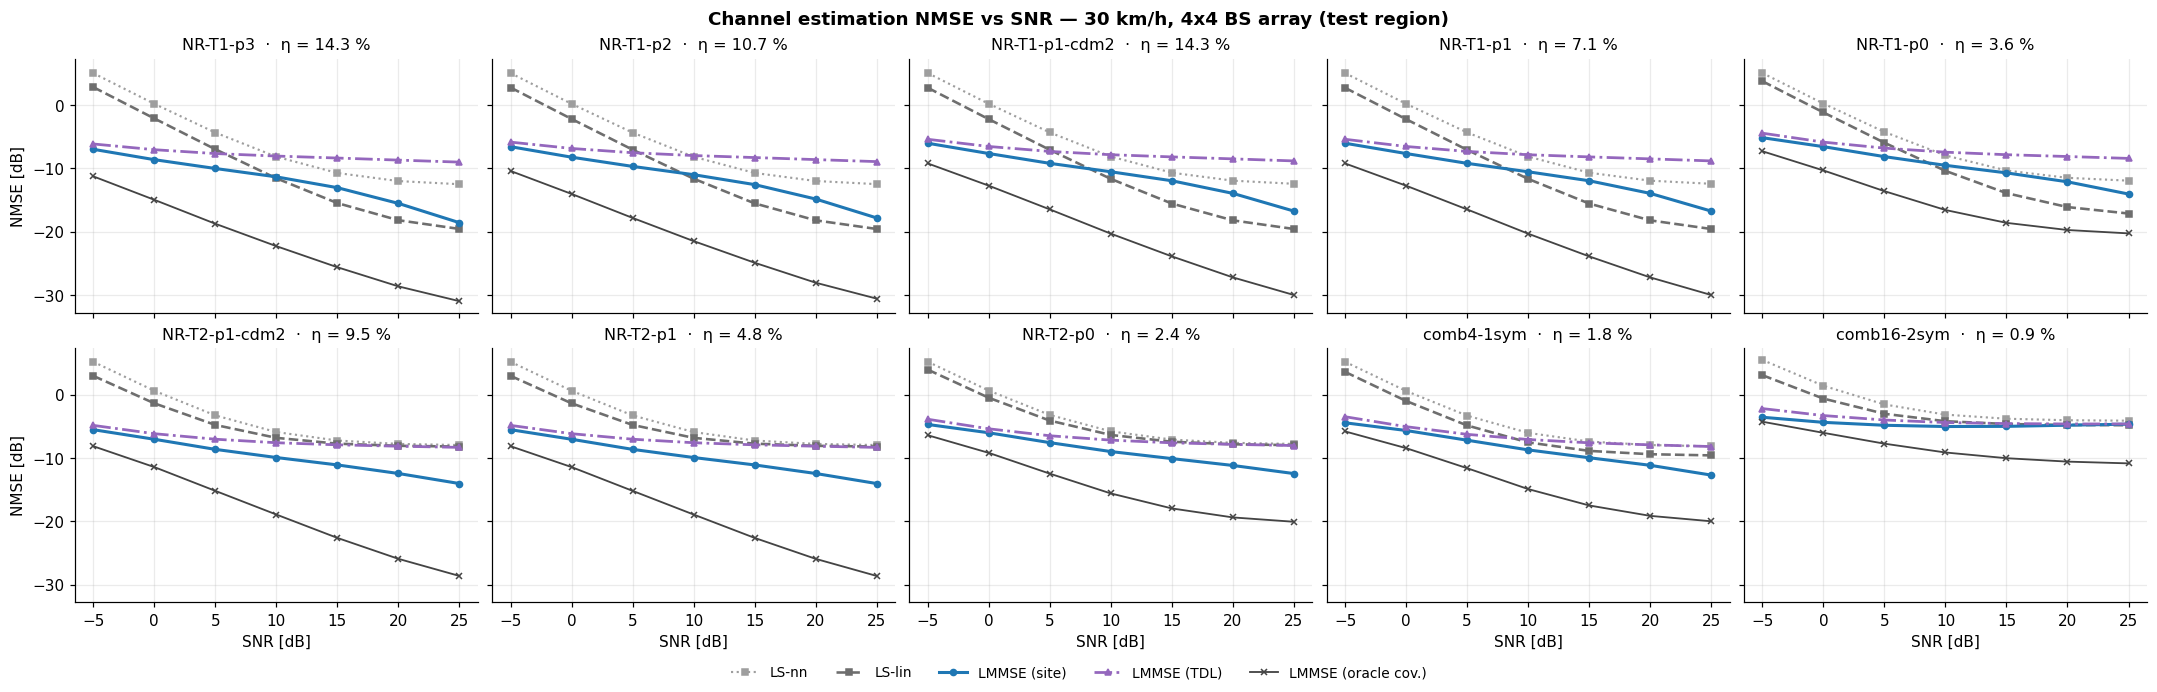

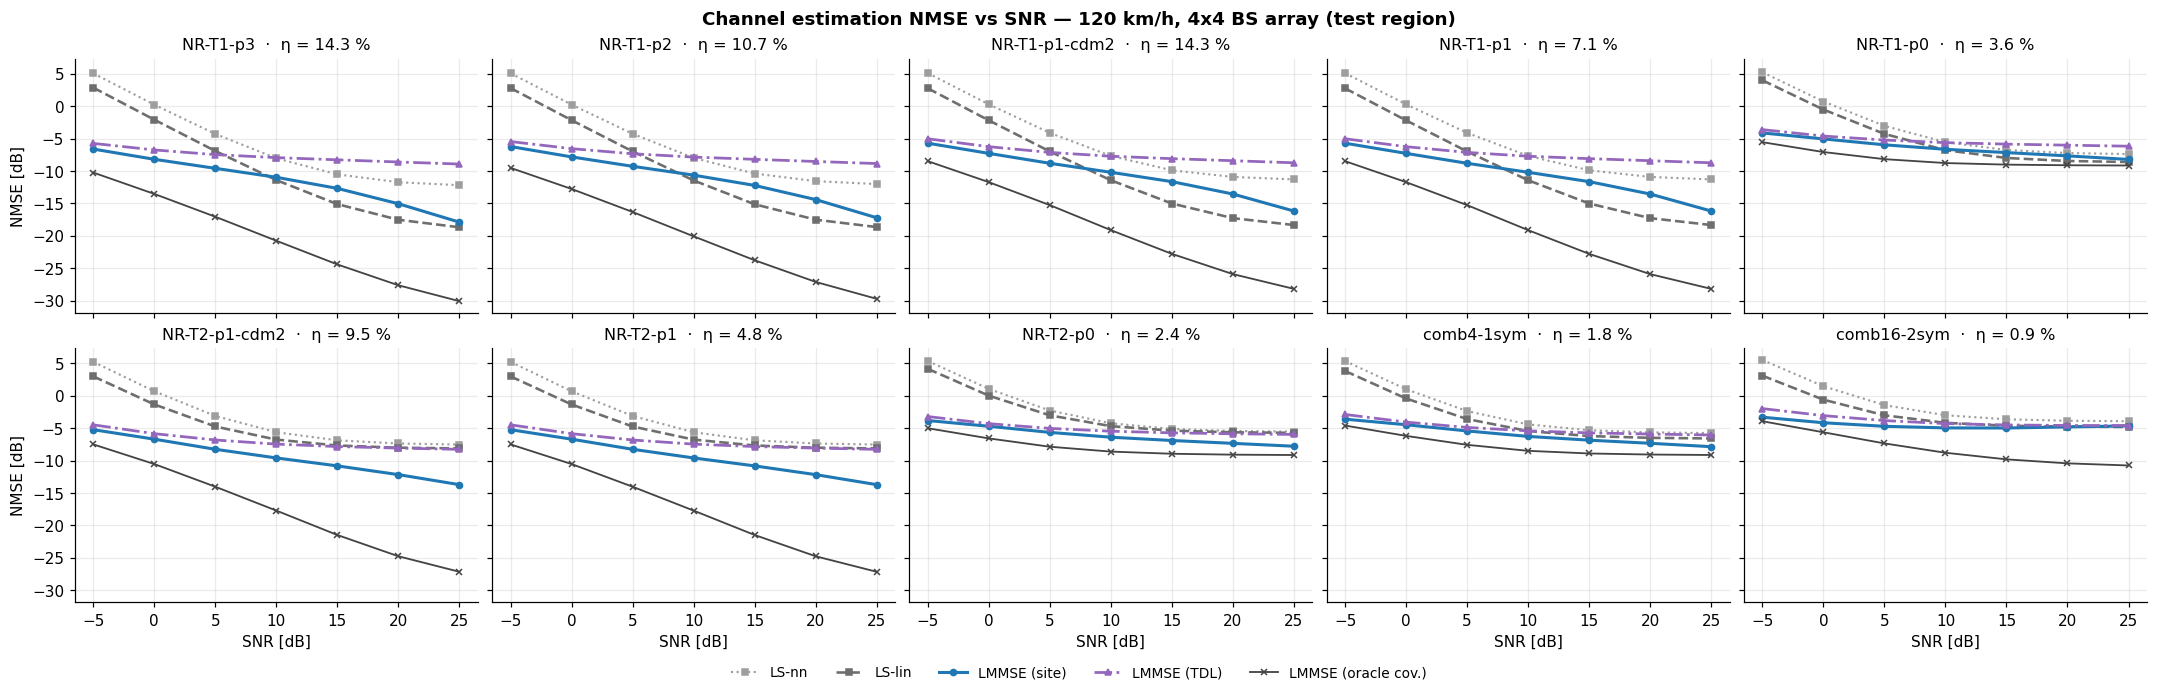


LS-lin NMSE @25 dB [dB]: Step-5 prediction vs measurement
       config  3: predicted  3: measured  30: predicted  30: measured  120: predicted  120: measured
     NR-T1-p3    -27.200001        -19.6     -27.200001         -19.6      -27.000000          -18.7
     NR-T1-p2    -27.200001        -19.6     -27.200001         -19.6      -26.799999          -18.6
NR-T1-p1-cdm2    -27.299999        -19.6     -27.200001         -19.6      -24.299999          -18.3
     NR-T1-p1    -27.299999        -19.6     -27.200001         -19.6      -24.299999          -18.3
     NR-T1-p0    -26.000000        -19.4     -18.400000         -17.1       -8.100000           -8.6
NR-T2-p1-cdm2    -27.299999         -8.2     -27.299999          -8.2      -23.900000           -8.1
     NR-T2-p1    -27.299999         -8.2     -27.299999          -8.2      -23.900000           -8.1
     NR-T2-p0    -26.000000         -8.2     -18.000000          -8.0       -7.000000           -5.7
   comb4-1sym    -26.299999     

In [35]:
def plot_nmse(v, est_names, cfgs=CONFIGS, store=NMSE):
    fig, axs, r, c_ = make_axes(len(cfgs), sharex=True, sharey=True)
    for k, (ax, c) in enumerate(zip(axs, cfgs)):
        for n in est_names:
            if (c["name"], v, n) in store:
                ax.plot(SNR_GRID, dB(store[(c["name"], v, n)]), label=n, ms=4, **est_style(n))
        ax.set_title(f"{c['name']}  ·  η = {100 * c['eta']:.1f} %")
        if k % c_ == 0: ax.set_ylabel("NMSE [dB]")
        if k // c_ == r - 1 or k + c_ >= len(cfgs): ax.set_xlabel("SNR [dB]")
    shared_legend(fig, axs)
    fig.suptitle(f"Channel estimation NMSE vs SNR — {v} km/h, {M_EVAL}x{M_EVAL} BS array (test region)", fontsize=12, fontweight="bold")
    plt.show()

for v in SPEEDS:                                   # 3, 30 and 120 km/h
    plot_nmse(v, ["LS-nn", "LS-lin", "LMMSE (site)", "LMMSE (TDL)", "LMMSE (oracle cov.)"])

# Compare measured 25 dB LS-lin NMSE with the Step 5 prediction (interpolation error + LS noise term)
rows = []
for c in CONFIGS:
    r = {"config": c["name"]}
    for v in SPEEDS:
        pr = PRED[PRED.config == c["name"]][f"{v}km/h: pred. NMSE_lin[dB]"].item()
        At, Af = interp_mats(c, "lin"); g = (At ** 2).sum(1).mean() * (Af ** 2).sum(1).mean()     # LS noise gain of the interpolator
        tot = 10 ** (pr / 10) + g * 10 ** (-SNR_GRID[-1] / 10)                                    # interpolation error + noise
        r[f"{v}: predicted"] = round(10 * np.log10(tot), 1); r[f"{v}: measured"] = round(10 * np.log10(NMSE[(c['name'], v, 'LS-lin')][-1]), 1)
    rows.append(r)
print("\nLS-lin NMSE @25 dB [dB]: Step-5 prediction vs measurement"); print(pd.DataFrame(rows).to_string(index=False))
print("\nSite-specific vs generic covariance, NMSE @15 dB [dB] (positive gap = benefit of site knowledge):")
print(pd.DataFrame([{ "config": c["name"], **{f"{v}km/h": round(10*np.log10(NMSE[(c['name'],v,'LMMSE (TDL)')][4] / NMSE[(c['name'],v,'LMMSE (site)')][4]), 1) for v in SPEEDS}} for c in CONFIGS]).to_string(index=False))

## Step 7 — Learned channel estimators
Two learned models, both trained on the **training region only**, model selection on the **validation region**, results on the **test region**:

1. **Learned linear estimator** (a single linear layer `H_hat = W y`). Its optimum under the MSE loss is the closed-form ridge solution, trained on 8-PRB windows for every (SNR, speed).
   This is the learned counterpart of LMMSE, so the comparison shows how much the data-driven filter loses or gains against covariance-based LMMSE.
2. **CNN** that treats the time-frequency grid as an image. Input: LS + linear interpolated grid (Re / Im), pilot mask, SNR plane and speed plane. Output: a correction to the LS-lin grid (residual learning).
   Fully convolutional, so it is trained on 14 x 96 crops and applied to the full 14 x 288 slot.

**One model per pilot configuration** (not one model with a mask input): the pattern fixes which interpolation problem the network must solve, the networks are small, and per-configuration models avoid
trading accuracy between very different patterns. The mask plane is still provided so that a shared model can be trained later. The loss is NMSE **in dB** so that low and high SNR count equally
(a linear loss is dominated by low SNR and leaves the high-SNR region untrained).

In [36]:
# ---- windowed data + closed-form learned linear filter (numpy) ----
def to_windows(H):
    n, A, T, F = H.shape
    return H.reshape(n * A, T, F // WIN, WIN).transpose(0, 2, 1, 3).reshape(-1, T, WIN)

def fit_ridge(Hw, cfg, sig2, Hv=None, reps=3, lams=(1e-4, 1e-3, 1e-2, 1e-1), seed=0):
    """Ridge filter W [D, L]; the regularisation `lam` is picked on the validation windows Hv (if given)."""
    rng = np.random.default_rng(seed)
    Hp = Hw[:, cfg["Tp"]][:, :, cfg["Fp_w"]]; B = len(Hw); L = Hp.shape[1] * Hp.shape[2]
    Hf = Hw.reshape(B, -1)
    Ryy = np.zeros((L, L), np.complex128); Rhy = np.zeros((Hf.shape[1], L), np.complex128)
    for _ in range(reps):
        Y = (Hp + noise_like(Hp.shape, sig2, rng)).reshape(B, L)
        Ryy += Y.T @ Y.conj(); Rhy += Hf.T @ Y.conj()
    Ryy /= reps * B; Rhy /= reps * B
    solve = lambda lam: (Rhy @ np.linalg.inv(Ryy + lam * np.trace(Ryy).real / L * np.eye(L))).astype(np.complex64)
    if Hv is None: return solve(lams[0])
    Hvp = Hv[:, cfg["Tp"]][:, :, cfg["Fp_w"]]
    Yv = (Hvp + noise_like(Hvp.shape, sig2, np.random.default_rng(seed + 99))).reshape(len(Hv), L)
    errs = [np.mean(np.abs(Yv @ W.T - Hv.reshape(len(Hv), -1)) ** 2) for W in map(solve, lams)]
    return solve(lams[int(np.argmin(errs))])

def fit_all_ridge(cfg, Htr_=None, vtr_=None, speeds=SPEEDS):
    Htr_ = Htr if Htr_ is None else Htr_; vtr_ = vtr if vtr_ is None else vtr_
    out = {}
    for v in speeds:
        Hw, Hv = to_windows(Htr_[vtr_ == v]), to_windows(Hva_v[v])
        for snr in SNR_GRID: out[(snr, v)] = fit_ridge(Hw, cfg, 10 ** (-snr / 10), Hv=Hv)
    return out

def window_filter_est(Wd, cfg, v_cond):
    """Wd: {(snr, speed): W[D, L]}. v_cond: the speed the filter was designed for (differs from the true speed in mismatch tests)."""
    def fn(Hp, s2):
        W = Wd[(int(round(-10 * np.log10(s2))), v_cond)]
        return run_windowed(lambda Y: (Y.reshape(len(Y), -1) @ W.T).reshape(-1, NSYM, WIN), Hp, cfg)
    return fn

In [37]:
# [needs-torch]  Learned estimator 2: CNN on the time-frequency grid
import gc, torch, torch.nn as nn
device = globals().get("device") or torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CNNEst(nn.Module):
    """Planes in: Re/Im of the LS+linear-interpolated grid, pilot mask, SNR, speed.  Out: LS-lin grid + correction.
    Dilated convolutions along frequency widen the receptive field to ~33 subcarriers; the last layer starts at zero,
    so the untrained network is exactly LS-lin (residual learning)."""
    def __init__(self, ch=24, dil=(1, 2, 4, 8)):
        super().__init__()
        layers, cin = [], 5
        for d in dil:
            layers += [nn.Conv2d(cin, ch, 3, padding=(1, d), dilation=(1, d)), nn.ReLU()]; cin = ch
        self.body = nn.Sequential(*layers); self.out = nn.Conv2d(ch, 2, 3, padding=1)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)

    def forward(self, ls, mask, snr_db, speed):
        B, _, T, F = ls.shape
        sn = torch.as_tensor(snr_db, dtype=torch.float32, device=ls.device).reshape(-1, 1, 1, 1).expand(B, 1, T, F) / 30.0
        sp = torch.full((B, 1, T, F), math.log10(speed) / 2.0, device=ls.device)
        x = torch.cat([ls, mask.expand(B, -1, -1, -1), sn, sp], 1)
        return ls + self.out(self.body(x))

def _mask_t(cfg): return torch.as_tensor(cfg["pilot"].astype(np.float32)).to(device)[None, None]          # [1,1,T,F]

def train_cnn(cfg, steps=1500, B=32, lr=2e-3, train_speeds=SPEEDS, seed=0, val_every=250):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    Tp, Fp = torch.as_tensor(cfg["Tp"], device=device), torch.as_tensor(cfg["Fp"], device=device)
    At, Af = [torch.as_tensor(m).to(device) for m in interp_mats(cfg, "lin")]
    mask = _mask_t(cfg)
    flat = lambda X: torch.as_tensor(X.reshape(-1, NSYM, NSC)).to(device)                  # every antenna = one grid
    tr = {v: flat(Htr[vtr == v]) for v in train_speeds}
    va = {}
    for v in train_speeds:
        h = flat(Hva_v[v]); va[v] = h[torch.as_tensor(np.random.default_rng(3).permutation(len(h))[:96], device=device)]
    g = torch.Generator(device=device); g.manual_seed(1234)                                # fixed validation noise
    vn = {(v, s): torch.randn(len(va[v]), len(cfg["Tp"]), len(cfg["Fp"]), dtype=torch.complex64, device=device, generator=g)
          for v in train_speeds for s in SNR_GRID}
    model = CNNEst().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))

    def nmse(Hb, snr, v, noise=None, crop=None):
        Y = Hb[:, Tp][:, :, Fp]
        if noise is None: noise = torch.randn(Y.shape, dtype=torch.complex64, device=device)
        Y = Y + noise * math.sqrt(10 ** (-snr / 10))                                       # LS estimate at the pilots
        ls = torch.stack([At @ Y.real @ Af.T, At @ Y.imag @ Af.T], 1)                     # LS-lin grid [B,2,T,F]
        tgt = torch.stack([Hb.real, Hb.imag], 1); m = mask
        if crop is not None: ls, tgt, m = ls[..., crop:crop + WIN], tgt[..., crop:crop + WIN], m[..., crop:crop + WIN]
        return (model(ls, m, snr, v) - tgt).pow(2).sum() / tgt.pow(2).sum()

    def val_score():
        model.eval()
        with torch.no_grad():
            sc = float(np.mean([10 * math.log10(nmse(va[v], s, v, vn[(v, s)]).item()) for v in train_speeds for s in SNR_GRID]))
        model.train(); return sc

    best = val_score(); best_state = {k: x.detach().clone() for k, x in model.state_dict().items()}      # step 0 == LS-lin
    print(f"  [CNN {cfg['name']}] step 0 (= LS-lin) val {best:6.2f} dB")
    model.train()
    for it in range(1, steps + 1):
        v = int(rng.choice(train_speeds)); snr = float(rng.uniform(-5, 25)); c0 = int(rng.choice([0, 48, 96, 144, 192]))   # crops keep the pilot pattern aligned
        loss = nmse(tr[v][torch.randint(len(tr[v]), (B,), device=device)], snr, v, crop=c0)
        opt.zero_grad(); (10 * torch.log10(loss)).backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if it % val_every == 0 or it == steps:
            sc = val_score()
            if sc < best: best, best_state = sc, {k: x.detach().clone() for k, x in model.state_dict().items()}
            print(f"  [CNN {cfg['name']}] step {it:5d}  train {10 * math.log10(loss.item()):6.2f} dB | val {sc:6.2f} dB | best {best:6.2f} dB")
    model.load_state_dict(best_state); model.eval(); return model

def cnn_est(model, cfg, v, bs=64):
    """Estimator function: noisy LS pilots [..., Tp, Fp] -> H_hat [..., NSYM, NSC]."""
    mask = _mask_t(cfg)
    def fn(Hp, s2):
        ls = est_ls(Hp, cfg, "lin"); lead = ls.shape[:-2]; flat = ls.reshape(-1, NSYM, NSC); out = []
        with torch.no_grad():
            for i in range(0, len(flat), bs):
                x = torch.as_tensor(np.stack([flat[i:i + bs].real, flat[i:i + bs].imag], 1)).to(device)
                y = model(x, mask, -10 * math.log10(s2), v)
                out.append(torch.complex(y[:, 0], y[:, 1]).cpu().numpy())
        return np.concatenate(out).reshape(*lead, NSYM, NSC).astype(np.complex64)
    return fn

In [38]:
# ---- learned linear filter: fit on the training region, evaluate on the test region (numpy) ----
LEARN_CONFIGS = ["NR-T1-p3", "NR-T1-p1", "NR-T1-p0", "NR-T2-p0", "comb4-1sym", "comb16-2sym"]
FILTERS = {}            # cfg name -> {"ridge": {(snr, speed): W}}

def run_ridge(names=LEARN_CONFIGS):
    for n in names:
        c = CFG[n]; FILTERS.setdefault(n, {})["ridge"] = Wd = fit_all_ridge(c)
        for v in SPEEDS: NMSE[(n, v, "Ridge (learned linear)")] = nmse_curve(Hte_v[v], c, window_filter_est(Wd, c, v))
        print("learned linear filter done:", n)

run_ridge()

learned linear filter done: NR-T1-p3
learned linear filter done: NR-T1-p1
learned linear filter done: NR-T1-p0
learned linear filter done: NR-T2-p0
learned linear filter done: comb4-1sym
learned linear filter done: comb16-2sym


In [39]:
# [needs-torch]  Train the CNN once per pilot configuration and evaluate on the test region
STEPS_CNN = 1500                  # lower (e.g. 600) for a quick test on CPU
CNN = {}
for n in LEARN_CONFIGS:
    c = CFG[n]; t0 = time.time(); gc.collect(); torch.cuda.empty_cache()
    CNN[n] = train_cnn(c, steps=STEPS_CNN)
    for v in SPEEDS:
        NMSE[(n, v, "CNN (learned)")] = nmse_curve(Hte_v[v], c, cnn_est(CNN[n], c, v), reps=1)     # reps=1: CNN inference is the slow part on CPU
    print(f"{n}: CNN trained and evaluated in {time.time() - t0:.0f}s")
torch.save({"filters": FILTERS, "cnn": {k: m.state_dict() for k, m in CNN.items()}}, "learned_estimators.pt")

  [CNN NR-T1-p3] step 0 (= LS-lin) val -11.74 dB
  [CNN NR-T1-p3] step   250  train -24.92 dB | val -16.27 dB | best -16.27 dB
  [CNN NR-T1-p3] step   500  train -14.52 dB | val -17.51 dB | best -17.51 dB
  [CNN NR-T1-p3] step   750  train -15.35 dB | val -17.84 dB | best -17.84 dB
  [CNN NR-T1-p3] step  1000  train -14.37 dB | val -18.26 dB | best -18.26 dB
  [CNN NR-T1-p3] step  1250  train  -7.68 dB | val -18.45 dB | best -18.45 dB
  [CNN NR-T1-p3] step  1500  train -13.83 dB | val -18.48 dB | best -18.48 dB
NR-T1-p3: CNN trained and evaluated in 13s
  [CNN NR-T1-p1] step 0 (= LS-lin) val -11.80 dB
  [CNN NR-T1-p1] step   250  train -24.74 dB | val -16.13 dB | best -16.13 dB
  [CNN NR-T1-p1] step   500  train -13.85 dB | val -16.85 dB | best -16.85 dB
  [CNN NR-T1-p1] step   750  train -14.74 dB | val -17.44 dB | best -17.44 dB
  [CNN NR-T1-p1] step  1000  train -13.52 dB | val -17.53 dB | best -17.53 dB
  [CNN NR-T1-p1] step  1250  train  -6.58 dB | val -17.85 dB | best -17.85 dB
 

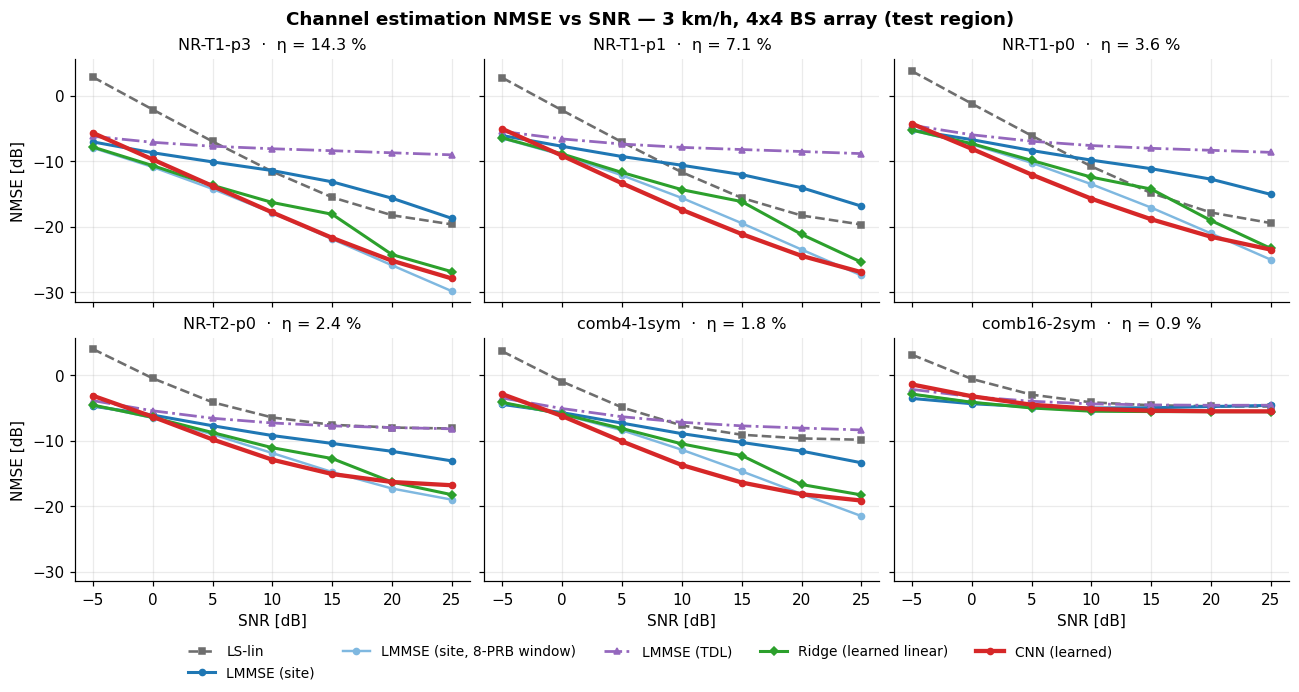

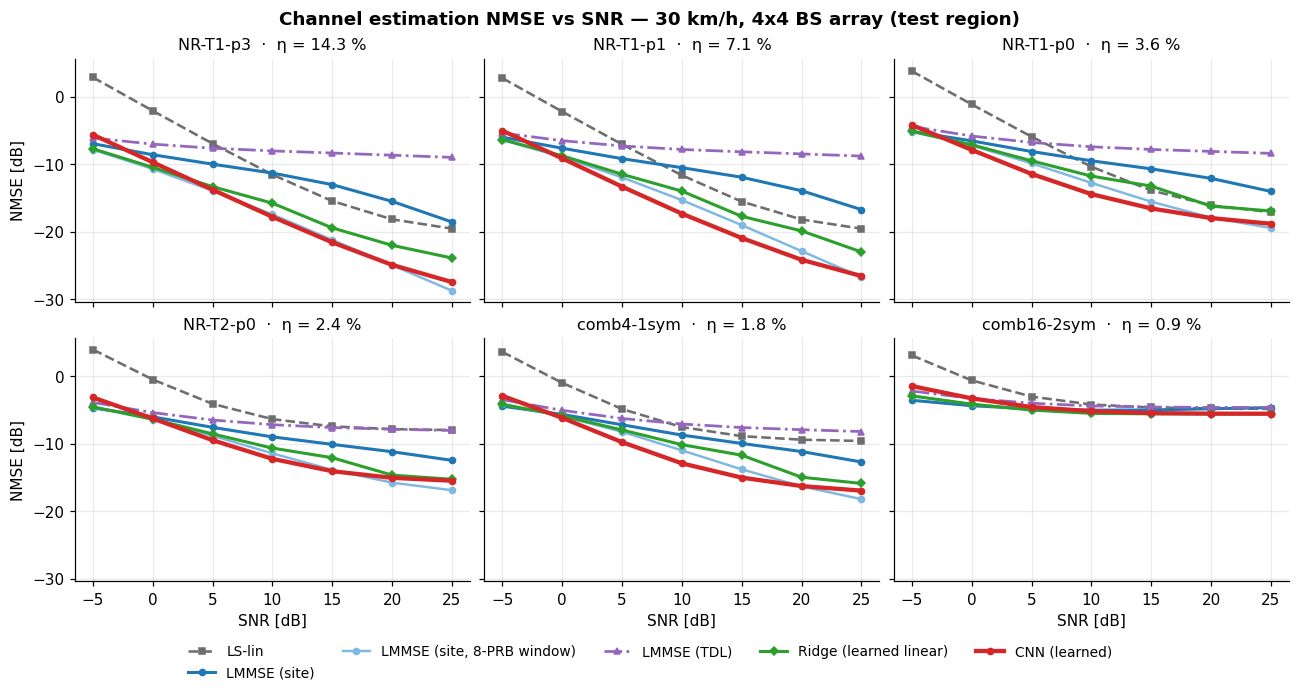

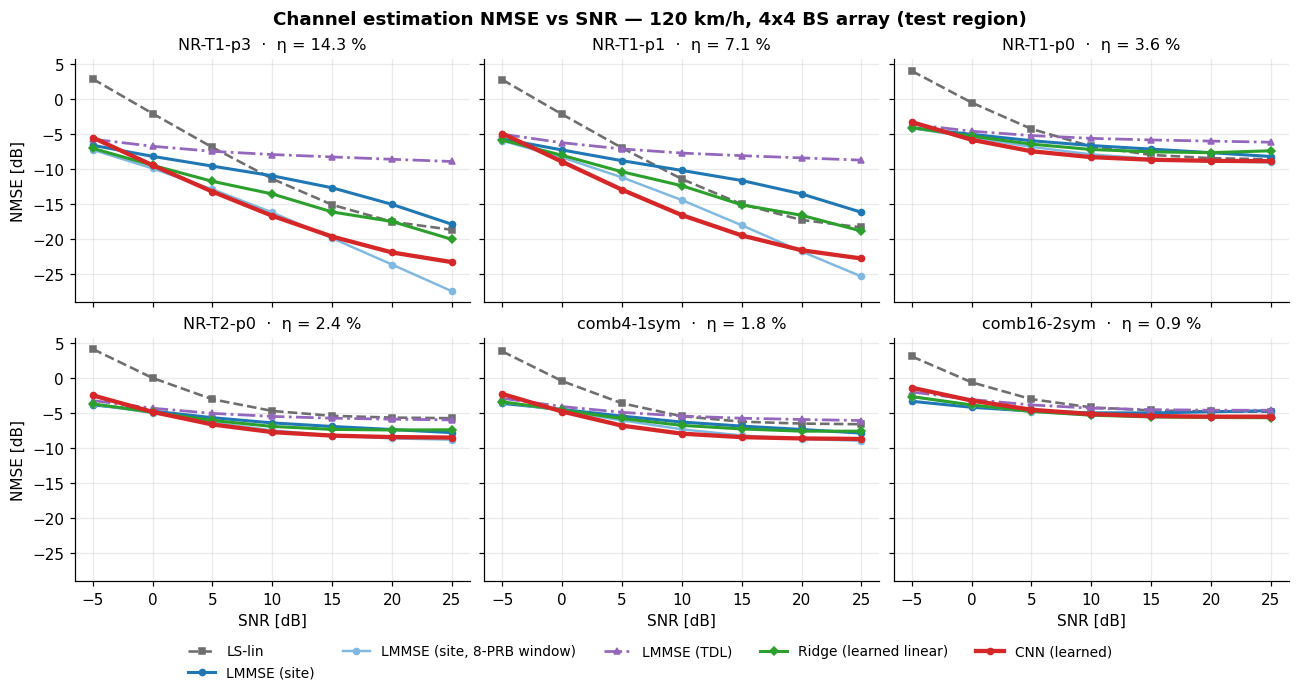

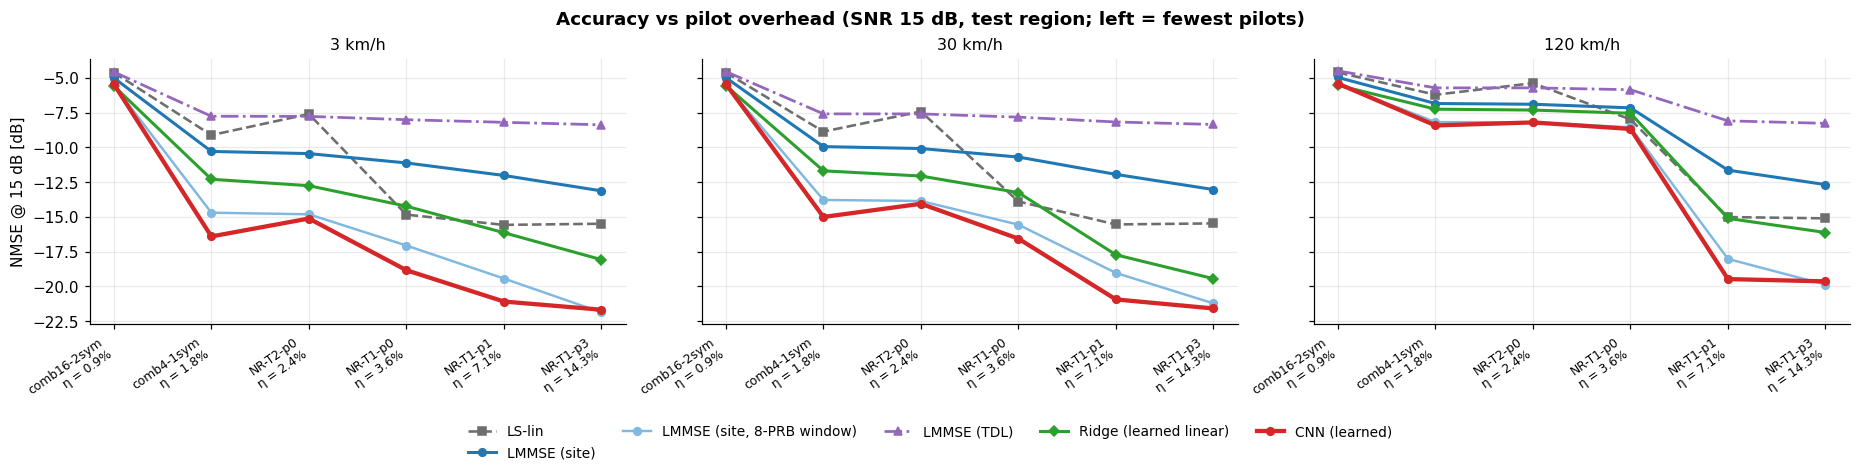

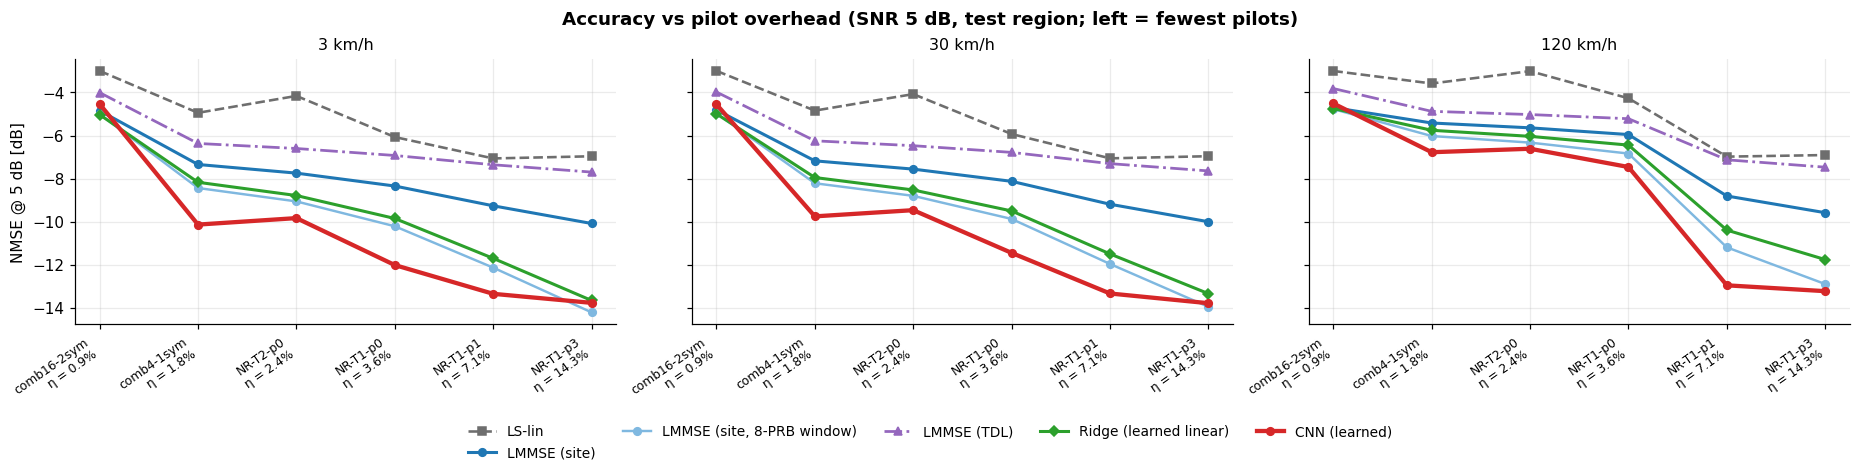

In [40]:
LEARNED = ["LS-lin", "LMMSE (site)", "LMMSE (site, 8-PRB window)", "LMMSE (TDL)", "Ridge (learned linear)", "CNN (learned)"]
for v in SPEEDS:                                   # 3, 30 and 120 km/h
    plot_nmse(v, LEARNED, cfgs=[CFG[n] for n in LEARN_CONFIGS])

def plot_nmse_vs_eta(snr=15, est_names=LEARNED):
    '''NMSE at one SNR for every pilot configuration, ordered by overhead (evenly spaced so the labels stay readable).'''
    cs = sorted([CFG[n] for n in LEARN_CONFIGS], key=lambda c: c["eta"]); k = SNR_GRID.index(snr); x = np.arange(len(cs))
    fig, axs, r, c_ = make_axes(len(SPEEDS), w=5.6, h=4.2, sharey=True)
    for ax, v in zip(axs, SPEEDS):
        for n in est_names:
            if all((c["name"], v, n) in NMSE for c in cs):
                ax.plot(x, [dB(NMSE[(c["name"], v, n)][k]) for c in cs], label=n, **est_style(n))
        ax.set_xticks(x); ax.set_xticklabels([f"{c['name']}\nη = {100 * c['eta']:.1f}%" for c in cs], fontsize=8, rotation=35, ha="right")
        ax.set_title(f"{v} km/h")
    axs[0].set_ylabel(f"NMSE @ {snr} dB [dB]"); shared_legend(fig, axs)
    fig.suptitle(f"Accuracy vs pilot overhead (SNR {snr} dB, test region; left = fewest pilots)", fontsize=12, fontweight="bold"); plt.show()

plot_nmse_vs_eta(15); plot_nmse_vs_eta(5)

In [41]:
# ---- where do the learned estimators win on the TEST region? ----
def scoreboard(target, rivals):
    rows = []
    for n in LEARN_CONFIGS:
        for v in SPEEDS:
            t = 10 * np.log10(NMSE[(n, v, target)])
            gap = {r: float(np.mean(10 * np.log10(NMSE[(n, v, r)]) - t)) for r in rivals}        # > 0: target better (dB, mean over SNR)
            rows.append({"config": n, "speed": v, **{r: round(g, 2) for r, g in gap.items()}, "beats all": all(g > 0 for g in gap.values())})
    df = pd.DataFrame(rows)
    print(f"Mean NMSE advantage of {target} [dB], averaged over SNR (positive = better than the rival)")
    print(df.to_string(index=False)); print(f"-> beats ALL listed rivals in {int(df['beats all'].sum())}/{len(df)} (config, speed) cases\n")
    return df

SCORE_CNN = scoreboard("CNN (learned)", ["LS-lin", "LMMSE (site)", "LMMSE (site, 8-PRB window)", "LMMSE (TDL)", "Ridge (learned linear)"])
SCORE_RIDGE = scoreboard("Ridge (learned linear)", ["LS-lin", "LMMSE (site, 8-PRB window)", "LMMSE (TDL)"])

for v in (3, 120):
    print(f"NMSE @15 dB [dB], {v} km/h (lower is better)")
    print(pd.DataFrame([{"config": n, **{e: round(10 * np.log10(NMSE[(n, v, e)][4]), 1) for e in LEARNED if (n, v, e) in NMSE}} for n in LEARN_CONFIGS]).to_string(index=False))

Mean NMSE advantage of CNN (learned) [dB], averaged over SNR (positive = better than the rival)
     config  speed  LS-lin  LMMSE (site)  LMMSE (site, 8-PRB window)  LMMSE (TDL)  Ridge (learned linear)  beats all
   NR-T1-p3      3    7.22          5.29                       -0.97         9.51                    0.59      False
   NR-T1-p3     30    7.14          5.27                       -0.57         9.44                    1.18      False
   NR-T1-p3    120    5.84          4.11                       -1.07         8.00                    2.03      False
   NR-T1-p1      3    6.53          5.84                        0.54         9.23                    1.91       True
   NR-T1-p1     30    6.44          5.79                        0.75         9.15                    2.19       True
   NR-T1-p1    120    5.54          4.84                        0.31         7.99                    2.86       True
   NR-T1-p0      3    5.36          4.99                        0.63         7.71    

In [42]:

def latency(fn, Hp, reps=3):
    fn(Hp, 0.01); t0 = time.perf_counter()
    for _ in range(reps): fn(Hp, 0.01)
    return (time.perf_counter() - t0) / reps / int(np.prod(Hp.shape[:-2])) * 1e3

cnn_macs = lambda m: sum(p.numel() for n_, p in m.named_parameters() if n_.endswith("weight")) * NSYM * NSC
rows = []
for n in LEARN_CONFIGS:
    c = CFG[n]; Tp_, Fp_ = len(c["Tp"]), len(c["Fp"]); L = Tp_ * len(c["Fp_w"]); D = NSYM * WIN; nw = NSC // WIN
    Hp = pilots_of(Hte_v[120][:4], c)
    lm_flops = 8 * (2 * (Tp_ ** 2 * Fp_ + Tp_ * Fp_ ** 2) + NSYM * Tp_ * Fp_ + NSYM * Fp_ * NSC)
    rows.append({"config": n,
                 "LMMSE: params": "0 (stores R_t, R_f)", "LMMSE: FLOPs/grid": lm_flops, "LMMSE: ms/grid": round(latency(lmmse("site", c, 120), Hp), 3),
                 "Linear: params (real)": 2 * D * L, "Linear: FLOPs/grid": 8 * D * L * nw, "Linear: ms/grid": round(latency(window_filter_est(FILTERS[n]["ridge"], c, 120), Hp), 3),
                 "CNN: params": sum(p.numel() for p in CNN[n].parameters()), "CNN: FLOPs/grid": 2 * cnn_macs(CNN[n]), "CNN: ms/grid": round(latency(cnn_est(CNN[n], c, 120), Hp), 3)})
print(pd.DataFrame(rows).set_index("config").T.to_string())
print("\nDevice for the CNN:", device, "| LMMSE and the linear filter run in numpy on the CPU.")

config                            NR-T1-p3             NR-T1-p1             NR-T1-p0             NR-T2-p0           comb4-1sym          comb16-2sym
LMMSE: params          0 (stores R_t, R_f)  0 (stores R_t, R_f)  0 (stores R_t, R_f)  0 (stores R_t, R_f)  0 (stores R_t, R_f)  0 (stores R_t, R_f)
LMMSE: FLOPs/grid                  6073344              5349888              4995072              3256320              2414592               596160
LMMSE: ms/grid                        0.16                0.148                0.113                0.075                0.061                0.024
Linear: params (real)               516096               258048               129024                86016                64512                32256
Linear: FLOPs/grid                 6193152              3096576              1548288              1032192               774144               387072
Linear: ms/grid                      0.061                0.053                0.022                0.017       

## Step 8 — Link-level impact of pilot overhead
Generic OFDM chain for every pattern: `TBEncoder -> Mapper -> resource grid -> ray-traced channel -> estimator -> MRC equaliser -> Demapper -> TBDecoder` (LDPC),
16-QAM, rate 0.5. The estimator output and its error variance (validation-set NMSE) are used for the equaliser and the LLR noise variance.
Goodput is reported with the NR transport block size (`TBS (1-BLER)/T_slot`) and with the number of data REs (`Qm R N_data (1-BLER)/T_slot`); `R(η)` is the information-theoretic bound with the measured NMSE.

In [43]:
from sionna.phy.nr import TBEncoder, TBDecoder, calculate_tb_size
from sionna.phy.mapping import Mapper, Demapper, BinarySource

class Link:
    def __init__(self, cfg, qm=4, rate=0.5, seed=0):
        self.cfg, self.qm, self.rate = cfg, qm, rate
        rng = np.random.default_rng(seed + 1)
        px = np.exp(1j * (np.pi / 4 + np.pi / 2 * rng.integers(0, 4, (len(cfg["Tp"]), len(cfg["Fp"]))))).astype(np.complex64)   # unit-power QPSK DMRS
        self.px = torch.as_tensor(px, device=device)
        tbs = calculate_tb_size(modulation_order=qm, target_coderate=rate, num_prbs=N_PRB, num_ofdm_symbols=NSYM,
                                num_dmrs_per_prb=int(np.ceil(cfg["n_reserved"] / N_PRB)))[0]                                # CHECK: first output = TBS
        self.enc = TBEncoder(target_tb_size=tbs, num_coded_bits=cfg["n_data"] * qm, target_coderate=rate, num_bits_per_symbol=qm)
        self.dec = TBDecoder(self.enc, num_bp_iter=20)
        self.src, self.map, self.dem = BinarySource(), Mapper("qam", qm), Demapper("app", "qam", qm)
        self.tbs = int(self.enc.tb_size)
        self.didx = torch.as_tensor(np.flatnonzero(~cfg["reserved"].reshape(-1)), device=device)
        self.Tp, self.Fp = torch.as_tensor(cfg["Tp"], device=device), torch.as_tensor(cfg["Fp"], device=device)

    @torch.no_grad()
    def run_batch(self, H, snr_db, est_fn, err_var):
        """H: [B, A, 14, 288] complex64 torch. est_fn(Yp_ls[np], sig2) -> H_hat[np]; None = perfect CSI. Returns #block errors."""
        B = H.shape[0]; sig2 = 10 ** (-snr_db / 10)
        s = self.map(self.enc(self.src([B, self.tbs]))).to(torch.complex64)                  # [B, n_data]
        x = torch.zeros(B, NSYM * NSC, dtype=torch.complex64, device=device); x[:, self.didx] = s
        x = x.view(B, NSYM, NSC); x[:, self.Tp[:, None], self.Fp[None, :]] = self.px
        y = H * x[:, None] + torch.randn_like(H) * math.sqrt(sig2)
        if est_fn is None: Hh = H
        else:
            Yp = y[:, :, self.Tp][:, :, :, self.Fp] / self.px                                  # LS at pilots
            Hh = torch.as_tensor(est_fn(Yp.cpu().numpy(), sig2)).to(device)
        den = (Hh.abs() ** 2).sum(1).clamp_min(1e-9)
        z = (Hh.conj() * y).sum(1) / den; no = ((sig2 + err_var) / den).to(torch.float32)
        llr = self.dem(z.reshape(B, -1)[:, self.didx], no.reshape(B, -1)[:, self.didx]).reshape(B, -1)
        _, ok = self.dec(llr)
        return int((~ok.reshape(B).bool()).sum())

In [44]:
# ---- estimator lookup and error variance used by the link-level cells ----
def get_est(e, cfg, v):
    """Returns f(Hp_noisy_LS, sigma2) -> H_hat, or None for perfect CSI."""
    if e == "Perfect CSI": return None
    if e == "LS-nn": return lambda Hp, s2: est_ls(Hp, cfg, "nn")
    if e == "LS-lin": return lambda Hp, s2: est_ls(Hp, cfg, "lin")
    if e == "LMMSE (site)": return lmmse("site", cfg, v)
    if e == "LMMSE (TDL)": return lmmse("tdl", cfg, v)
    if e == "Ridge (learned linear)": return window_filter_est(FILTERS[cfg["name"]]["ridge"], cfg, v)
    if e == "CNN (learned)": return cnn_est(CNN[cfg["name"]], cfg, v)
    raise KeyError(e)

_EV = {}
def err_var(e, cfg, v, snr):
    """Estimation error variance for a unit-power channel = NMSE of the estimator on the VALIDATION region at this SNR."""
    if e == "Perfect CSI": return 0.0
    key = (e, cfg["name"], v)
    if key not in _EV: _EV[key] = nmse_curve(Hva_v[v], cfg, get_est(e, cfg, v), reps=1)
    return float(_EV[key][SNR_GRID.index(snr)])

In [45]:
# [needs-sionna, needs-torch]  BLER sweep
LINK_CONFIGS = ["NR-T1-p3", "NR-T1-p1", "NR-T1-p0", "NR-T2-p0", "comb4-1sym"]       # >= 1 custom comb; all trained in Step 7
LINK_SPEEDS  = SPEEDS                               # 3, 30 and 120 km/h (use [3, 120] to save time: the assignment needs two)
LINK_EST     = ["Perfect CSI", "LS-lin", "LMMSE (site)", "Ridge (learned linear)", "CNN (learned)"]
LINK_SNR     = [0, 5, 10, 15, 20, 25]
MAX_SLOTS, MIN_ERR, BATCH = 1000, 50, 25            # raise MAX_SLOTS / MIN_ERR on a GPU for smoother curves
M_LINK = 2                                           # BS antennas for the link level: M_LINK x M_LINK (the M = 1, 2, 4 comparison is below)
BLER, TBS = {}, {}
Hte_t = {v: torch.as_tensor(view(ds, M_LINK, "test", v, base_only=True)[0]).to(device) for v in SPEEDS}
_rng = np.random.default_rng(7)

def run_link_sweep(cfgs=LINK_CONFIGS, speeds=LINK_SPEEDS, ests=LINK_EST, snrs=LINK_SNR):
    t0 = time.time()
    for cn in cfgs:
        link = Link(CFG[cn]); TBS[cn] = link.tbs
        for v in speeds:
            for e in ests:
                fn = get_est(e, CFG[cn], v); out = []
                for snr in snrs:
                    ev = err_var(e, CFG[cn], v, snr); errs = n = 0
                    while n < MAX_SLOTS and errs < MIN_ERR:
                        errs += link.run_batch(Hte_t[v][torch.as_tensor(_rng.integers(0, len(Hte_t[v]), BATCH), device=device)], snr, fn, ev); n += BATCH
                    out.append(errs / n)
                BLER[(e, cn, v)] = np.array(out)
                print(f"{cn:12s} {v:>3} km/h {e:14s} TBS={link.tbs} BLER={np.round(out, 3)}  [{time.time()-t0:.0f}s]")
run_link_sweep()
torch.save(dict(BLER=BLER, TBS=TBS), "link_results.pt")

NR-T1-p3       3 km/h Perfect CSI    TBS=6912 BLER=[0.96 0.   0.   0.   0.   0.  ]  [29s]
NR-T1-p3       3 km/h LS-lin         TBS=6912 BLER=[1.    0.057 0.    0.    0.    0.   ]  [58s]
NR-T1-p3       3 km/h LMMSE (site)   TBS=6912 BLER=[1.    0.12  0.106 0.102 0.03  0.016]  [84s]
NR-T1-p3       3 km/h Ridge (learned linear) TBS=6912 BLER=[1.    0.029 0.028 0.023 0.    0.   ]  [114s]
NR-T1-p3       3 km/h CNN (learned)  TBS=6912 BLER=[1.   0.02 0.   0.   0.   0.  ]  [145s]
NR-T1-p3      30 km/h Perfect CSI    TBS=6912 BLER=[0.973 0.    0.    0.    0.    0.   ]  [173s]
NR-T1-p3      30 km/h LS-lin         TBS=6912 BLER=[1.    0.056 0.    0.    0.    0.   ]  [201s]
NR-T1-p3      30 km/h LMMSE (site)   TBS=6912 BLER=[1.    0.128 0.122 0.083 0.028 0.024]  [228s]
NR-T1-p3      30 km/h Ridge (learned linear) TBS=6912 BLER=[1.    0.028 0.024 0.002 0.001 0.001]  [258s]
NR-T1-p3      30 km/h CNN (learned)  TBS=6912 BLER=[1.    0.026 0.    0.    0.    0.   ]  [290s]
NR-T1-p3     120 km/h Perfect

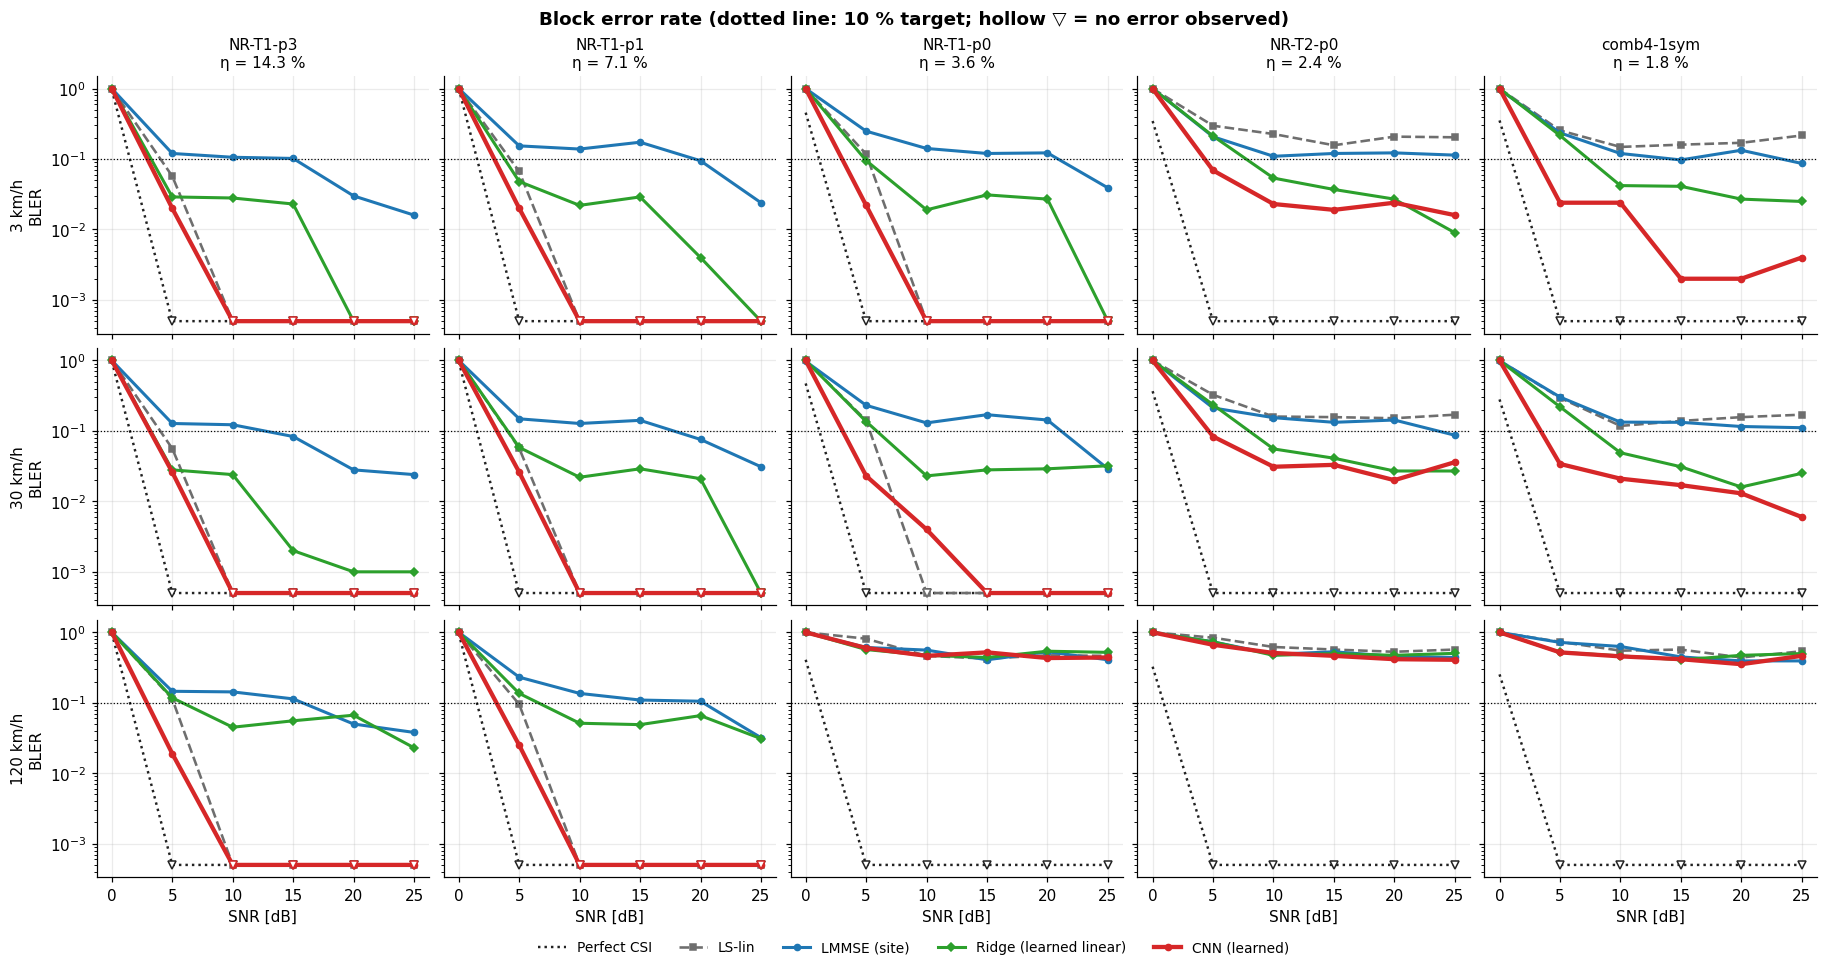

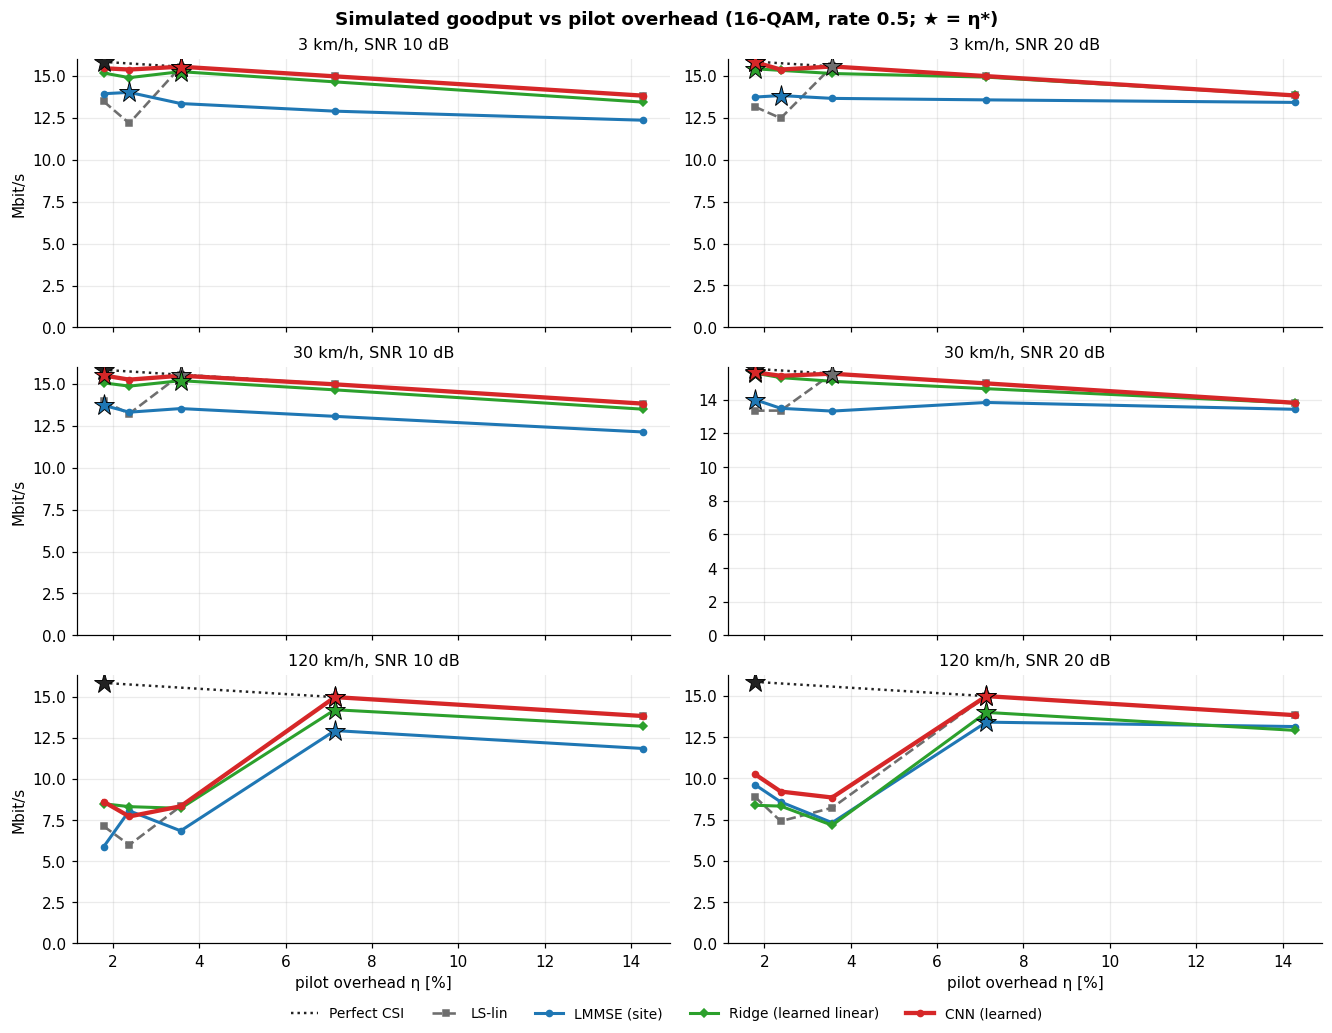

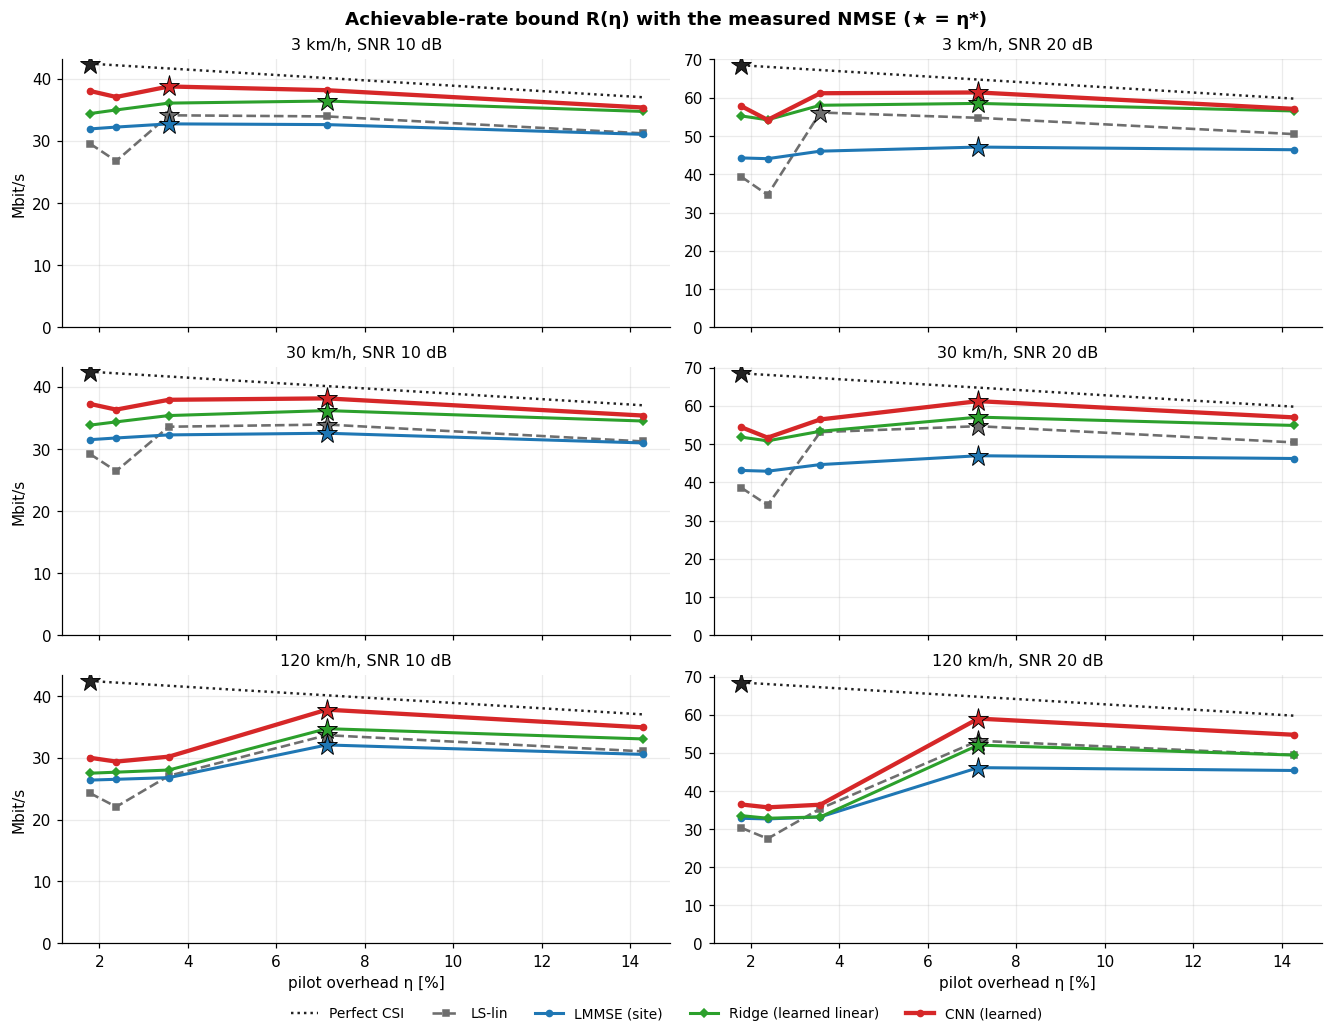

 speed  SNR              estimator  η* goodput_RE [%]  η* goodput_TBS [%]  η* R(η) [%]
     3   10            Perfect CSI               1.79                1.79         1.79
     3   10                 LS-lin               3.57                3.57         3.57
     3   10           LMMSE (site)               2.38                2.38         3.57
     3   10 Ridge (learned linear)               3.57                3.57         7.14
     3   10          CNN (learned)               3.57                3.57         3.57
     3   20            Perfect CSI               1.79                1.79         1.79
     3   20                 LS-lin               3.57                3.57         3.57
     3   20           LMMSE (site)               2.38                7.14         7.14
     3   20 Ridge (learned linear)               1.79                7.14         7.14
     3   20          CNN (learned)               1.79                3.57         7.14
    30   10            Perfect CSI         

In [46]:
# ---- BLER / goodput / R(eta) / eta* (numpy) ----
QM, RATE = 4, 0.5
def goodput_tbs(cn, e, v):  return TBS[cn] * (1 - BLER[(e, cn, v)]) / T_SLOT / 1e6                          # Mbit/s (NR TBS)
def goodput_re(cn, e, v):   return QM * RATE * CFG[cn]["n_data"] * (1 - BLER[(e, cn, v)]) / T_SLOT / 1e6   # Mbit/s (data-RE based)
def rate_bound(cn, e, v, snr, A):
    """R(eta) = (1-eta) log2(1 + rho ||h_hat||^2 / (1 + rho sigma_e^2)),  ||h_hat||^2 = A (1 - NMSE)   [bit / RE]."""
    nm = 0.0 if e == "Perfect CSI" else float(NMSE[(cn, v, e)][SNR_GRID.index(snr)])
    rho = 10 ** (snr / 10)
    return (1 - CFG[cn]["eta"]) * np.log2(1 + rho * A * (1 - nm) / (1 + rho * nm))
to_mbps = lambda bit_per_re: bit_per_re * NSYM * NSC / T_SLOT / 1e6

def plot_bler(speeds=None, cfgs=None):
    speeds, cfgs = speeds or LINK_SPEEDS, cfgs or LINK_CONFIGS
    floor = 1.0 / MAX_SLOTS
    fig, axs = plt.subplots(len(speeds), len(cfgs), figsize=(3.3 * len(cfgs), 2.9 * len(speeds)), sharex=True, sharey=True, squeeze=False, constrained_layout=True)
    for i, v in enumerate(speeds):
        for j, cn in enumerate(cfgs):
            ax = axs[i, j]
            for e in LINK_EST:
                if (e, cn, v) not in BLER: continue
                y = np.asarray(BLER[(e, cn, v)]); st = est_style(e); zero = y <= 0
                ax.semilogy(LINK_SNR, np.maximum(y, floor / 2), label=e, ms=4, **st)
                if zero.any():                                # BLER = 0: hollow marker on the floor instead of an invisible point
                    ax.plot(np.asarray(LINK_SNR)[zero], np.full(zero.sum(), floor / 2), ls="none", marker="v", ms=5, mfc="white", color=st["color"])
            ax.axhline(0.1, color="k", lw=0.8, ls=":"); ax.set_ylim(floor / 3, 1.5)
            if i == 0: ax.set_title(f"{cn}\nη = {100 * CFG[cn]['eta']:.1f} %", fontsize=10)
            if j == 0: ax.set_ylabel(f"{v} km/h\nBLER")
            if i == len(speeds) - 1: ax.set_xlabel("SNR [dB]")
    shared_legend(fig, [a for a in axs.ravel()])
    fig.suptitle("Block error rate (dotted line: 10 % target; hollow ▽ = no error observed)", fontsize=12, fontweight="bold"); plt.show()

def plot_goodput_vs_eta(snrs=(10, 20)):
    '''Two figures with their own scales: simulated goodput (data-RE based) and the information-theoretic bound R(eta); star = best overhead eta*.'''
    A = M_LINK ** 2; cs = sorted(LINK_CONFIGS, key=lambda c: CFG[c]["eta"]); et = [100 * CFG[c]["eta"] for c in cs]
    rows = []
    for kind, title in (("goodput", "Simulated goodput vs pilot overhead (16-QAM, rate 0.5; ★ = η*)"),
                        ("bound", "Achievable-rate bound R(η) with the measured NMSE (★ = η*)")):
        fig, axs = plt.subplots(len(LINK_SPEEDS), len(snrs), figsize=(6.0 * len(snrs), 3.1 * len(LINK_SPEEDS)), sharex=True, squeeze=False, constrained_layout=True)
        for i, v in enumerate(LINK_SPEEDS):
            for j, snr in enumerate(snrs):
                k = LINK_SNR.index(snr); ax = axs[i, j]
                for e in LINK_EST:
                    ge = {c: goodput_re(c, e, v)[k] for c in cs}; gt = {c: goodput_tbs(c, e, v)[k] for c in cs}
                    r = {c: rate_bound(c, e, v, snr, A) for c in cs}; st = est_style(e)
                    y = ge if kind == "goodput" else {c: to_mbps(r[c]) for c in cs}
                    ax.plot(et, [y[c] for c in cs], label=e, ms=4, **st)
                    best = max(y, key=lambda c: (round(y[c], 6), -CFG[c]["eta"]))              # ties -> smaller eta
                    ax.plot([100 * CFG[best]["eta"]], [y[best]], marker="*", ms=14, color=st["color"], mec="k", mew=0.6, ls="none", zorder=5)
                    if kind == "goodput":
                        pick = lambda d: round(100 * CFG[max(d, key=lambda c: (round(d[c], 6), -CFG[c]["eta"]))]["eta"], 2)
                        rows.append(dict(speed=v, SNR=snr, estimator=e, **{"η* goodput_RE [%]": pick(ge), "η* goodput_TBS [%]": pick(gt), "η* R(η) [%]": pick(r)}))
                ax.set_title(f"{v} km/h, SNR {snr} dB"); ax.set_ylim(bottom=0)       # zero-based axis: small differences stay small
                if j == 0: ax.set_ylabel("Mbit/s")
                if i == len(LINK_SPEEDS) - 1: ax.set_xlabel("pilot overhead η [%]")
        shared_legend(fig, [a_ for a_ in axs.ravel()]); fig.suptitle(title, fontsize=12, fontweight="bold"); plt.show()
    return pd.DataFrame(rows)

plot_bler()
ETA_STAR = plot_goodput_vs_eta()
print(ETA_STAR.to_string(index=False))
print("\nGoodput @ 15 dB, 120 km/h [Mbit/s]: NR-TBS based vs data-RE based")
print(pd.DataFrame([{"config": c, "η[%]": round(100 * CFG[c]["eta"], 2), "TBS": TBS[c], **{f"{e} TBS": round(goodput_tbs(c, e, 120)[LINK_SNR.index(15)], 2) for e in LINK_EST[1:]},
                     **{f"{e} RE": round(goodput_re(c, e, 120)[LINK_SNR.index(15)], 2) for e in LINK_EST[1:]}} for c in LINK_CONFIGS]).to_string(index=False))

### 8.x Effect of the number of BS antennas M
With M x M antennas every antenna needs its own channel estimate from the same pilots. The error per antenna does not shrink with M, so the combined
estimation error enters the SINR as `rho * M^2 (1-NMSE) / (1 + rho * NMSE)`: the array gain grows with M^2, the error term does not, so a poor
estimate caps the benefit of extra antennas at high SNR. The BLER curves below compare M = 1, 2, 4.

  3 km/h  M=1 ( 1 antennas) LS-lin         BLER=[1.    1.    0.108 0.    0.   ]
  3 km/h  M=1 ( 1 antennas) LMMSE (site)   BLER=[1.    1.    0.12  0.088 0.092]
  3 km/h  M=1 ( 1 antennas) CNN (learned)  BLER=[1.    1.    0.002 0.    0.   ]
  3 km/h  M=2 ( 4 antennas) LS-lin         BLER=[1.   0.05 0.   0.   0.  ]
  3 km/h  M=2 ( 4 antennas) LMMSE (site)   BLER=[1.    0.204 0.108 0.143 0.092]
  3 km/h  M=2 ( 4 antennas) CNN (learned)  BLER=[1.    0.028 0.    0.    0.   ]
  3 km/h  M=4 (16 antennas) LS-lin         BLER=[1. 0. 0. 0. 0.]
  3 km/h  M=4 (16 antennas) LMMSE (site)   BLER=[0.141 0.075 0.072 0.068 0.048]
  3 km/h  M=4 (16 antennas) CNN (learned)  BLER=[0.022 0.    0.    0.    0.   ]
 30 km/h  M=1 ( 1 antennas) LS-lin         BLER=[1.    1.    0.138 0.    0.   ]
 30 km/h  M=1 ( 1 antennas) LMMSE (site)   BLER=[1.    1.    0.122 0.08  0.08 ]
 30 km/h  M=1 ( 1 antennas) CNN (learned)  BLER=[1.    1.    0.032 0.    0.   ]
 30 km/h  M=2 ( 4 antennas) LS-lin         BLER=[1.    0.058

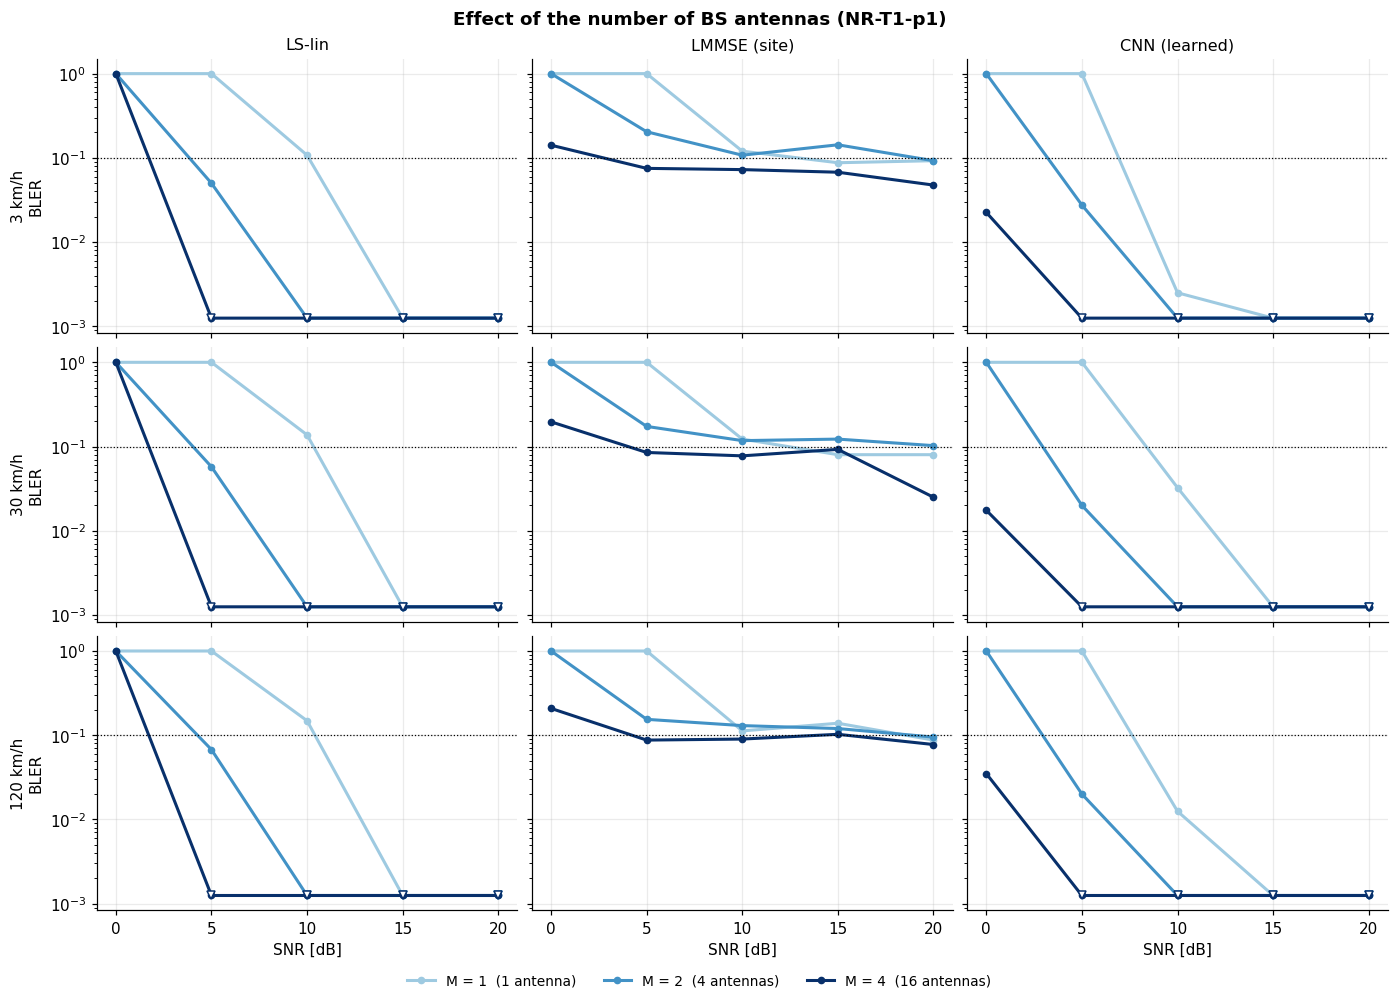

In [47]:
# [needs-sionna, needs-torch]  Step 2 / 8: BLER for M = 1, 2, 4 BS antennas (each antenna sees its own channel estimated from the SAME pilots)
M_CFG, M_SPEEDS, M_SNR, M_EST = "NR-T1-p1", SPEEDS, [0, 5, 10, 15, 20], ["LS-lin", "LMMSE (site)", "CNN (learned)"]
M_SLOTS = 400

def bler_vs_M(Ms=(1, 2, 4)):
    c = CFG[M_CFG]; link = Link(c); res = {}; rr = np.random.default_rng(11)
    for v in M_SPEEDS:
        for M_ in Ms:
            Hm = torch.as_tensor(view(ds, M_, "test", v, base_only=True)[0]).to(device)
            for e in M_EST:
                fn = get_est(e, c, v); out = []
                for snr in M_SNR:
                    ev = err_var(e, c, v, snr); errs = n = 0
                    while n < M_SLOTS and errs < 50:
                        errs += link.run_batch(Hm[torch.as_tensor(rr.integers(0, len(Hm), BATCH), device=device)], snr, fn, ev); n += BATCH
                    out.append(errs / n)
                res[(M_, e, v)] = np.array(out); print(f"{v:>3} km/h  M={M_} ({M_**2:>2} antennas) {e:14s} BLER={np.round(out, 3)}")
    return res

def plot_bler_vs_M(res, Ms=(1, 2, 4)):
    floor = 1.0 / M_SLOTS; cols = {1: "#9ecae1", 2: "#4292c6", 4: "#08306b"}
    fig, axs = plt.subplots(len(M_SPEEDS), len(M_EST), figsize=(4.2 * len(M_EST), 3.0 * len(M_SPEEDS)), sharex=True, sharey=True, squeeze=False, constrained_layout=True)
    for i, v in enumerate(M_SPEEDS):
        for j, e in enumerate(M_EST):
            ax = axs[i, j]
            for M_ in Ms:
                y = res[(M_, e, v)]
                ax.semilogy(M_SNR, np.maximum(y, floor / 2), marker="o", lw=2, ms=4, color=cols[M_], label=f"M = {M_}  ({M_ ** 2} antenna{'s' if M_ > 1 else ''})")
                z = y <= 0
                if z.any(): ax.plot(np.asarray(M_SNR)[z], np.full(z.sum(), floor / 2), ls="none", marker="v", mfc="white", color=cols[M_])
            ax.axhline(0.1, color="k", lw=0.8, ls=":"); ax.set_ylim(floor / 3, 1.5); ax.set_xticks(M_SNR)
            if i == 0: ax.set_title(e)
            if j == 0: ax.set_ylabel(f"{v} km/h\nBLER")
            if i == len(M_SPEEDS) - 1: ax.set_xlabel("SNR [dB]")
    shared_legend(fig, [a for a in axs.ravel()], ncol=3)
    fig.suptitle(f"Effect of the number of BS antennas ({M_CFG})", fontsize=12, fontweight="bold"); plt.show()

BLER_M = bler_vs_M(); plot_bler_vs_M(BLER_M)

## Step 9 — Reduced pilots and mismatch
(a) how much overhead each estimator saves at BLER <= 10 %, (b) train at one speed / test at another, (c) train at one site / test at another, compared with LMMSE using mismatched covariances.

In [48]:
# [needs-sionna, needs-torch]  (a) How much overhead can each estimator save at BLER <= 10 % ?
RED_CONFIGS = ["NR-T1-p3", "NR-T1-p1", "NR-T1-p0", "NR-T2-p0", "comb4-1sym", "comb16-2sym"]   # all trained in Step 7
SNR_T, BLER_T = 15, 0.10
run_link_sweep(cfgs=[c for c in RED_CONFIGS if c not in LINK_CONFIGS], speeds=LINK_SPEEDS, ests=LINK_EST, snrs=LINK_SNR)   # fills BLER for the new configs

def eta_min_table(snr=SNR_T, target=BLER_T):
    k = LINK_SNR.index(snr); rows = []
    for v in LINK_SPEEDS:
        for e in LINK_EST:
            ok = [c for c in RED_CONFIGS if (e, c, v) in BLER and BLER[(e, c, v)][k] <= target]
            best = min(ok, key=lambda c: CFG[c]["eta"]) if ok else None
            rows.append({"speed": v, "estimator": e, "smallest config with BLER<=10%": best, "η_min [%]": round(100 * CFG[best]["eta"], 2) if best else None,
                         **{c: round(float(BLER[(e, c, v)][k]), 3) for c in RED_CONFIGS if (e, c, v) in BLER}})
    return pd.DataFrame(rows)
ETA_MIN = eta_min_table(); print(f"BLER at {SNR_T} dB; target {BLER_T}"); print(ETA_MIN.to_string(index=False))

comb16-2sym    3 km/h Perfect CSI    TBS=7424 BLER=[0.27 0.   0.   0.   0.   0.  ]  [36s]
comb16-2sym    3 km/h LS-lin         TBS=7424 BLER=[1.    0.373 0.244 0.333 0.32  0.291]  [42s]
comb16-2sym    3 km/h LMMSE (site)   TBS=7424 BLER=[0.893 0.347 0.331 0.393 0.432 0.408]  [49s]
comb16-2sym    3 km/h Ridge (learned linear) TBS=7424 BLER=[1.    0.52  0.424 0.36  0.432 0.393]  [54s]
comb16-2sym    3 km/h CNN (learned)  TBS=7424 BLER=[1.    0.347 0.32  0.228 0.291 0.26 ]  [62s]
comb16-2sym   30 km/h Perfect CSI    TBS=7424 BLER=[0.236 0.    0.    0.    0.    0.   ]  [97s]
comb16-2sym   30 km/h LS-lin         TBS=7424 BLER=[1.    0.347 0.28  0.353 0.244 0.286]  [104s]
comb16-2sym   30 km/h LMMSE (site)   TBS=7424 BLER=[0.947 0.387 0.347 0.407 0.387 0.393]  [110s]
comb16-2sym   30 km/h Ridge (learned linear) TBS=7424 BLER=[1.    0.373 0.353 0.38  0.424 0.387]  [115s]
comb16-2sym   30 km/h CNN (learned)  TBS=7424 BLER=[1.    0.36  0.291 0.303 0.244 0.303]  [123s]
comb16-2sym  120 km/h Perf

In [49]:
# [needs-torch]  (b) speed mismatch:  train/design at 3 km/h -> test at 120 km/h and vice versa.  NMSE @ 15 dB.
CFG_MM, SNR_MM = "NR-T1-p0", 15              # reduced-pilot configuration where classical estimators struggle at 120 km/h
STEPS_MM = 1000

def mismatch_speed(cfg_name=CFG_MM, snr=SNR_MM):
    c, k, rows = CFG[cfg_name], SNR_GRID.index(snr), []
    db = lambda x: round(10 * np.log10(x), 2)
    for tr_v, te_v in ((3, 120), (120, 3)):
        r = {"train→test": f"{tr_v}→{te_v} km/h"}
        r["LMMSE matched"] = db(NMSE[(cfg_name, te_v, "LMMSE (site)")][k])
        r["LMMSE mismatched (R_t of train speed)"] = db(nmse_curve(Hte_v[te_v], c, lmmse("site", c, te_v, Rt_from=tr_v))[k])
        Wr = fit_all_ridge(c, speeds=[tr_v])
        r["Linear filter matched"] = db(NMSE[(cfg_name, te_v, "Ridge (learned linear)")][k])
        r["Linear filter mismatched"] = db(nmse_curve(Hte_v[te_v], c, window_filter_est(Wr, c, tr_v))[k])
        m = train_cnn(c, steps=STEPS_MM, train_speeds=[tr_v])                                # trained on ONE speed only
        r["CNN matched"] = db(NMSE[(cfg_name, te_v, "CNN (learned)")][k])
        r["CNN mismatched"] = db(nmse_curve(Hte_v[te_v], c, cnn_est(m, c, tr_v), reps=1)[k])
        rows.append(r)
    return pd.DataFrame(rows).set_index("train→test").T

MM = mismatch_speed(); print(f"NMSE [dB] @ {SNR_MM} dB, config {CFG_MM}"); print(MM.to_string())
print("\nDegradation (mismatched - matched) [dB]:")
for m in ("LMMSE", "Linear filter", "CNN"):
    a = [c for c in MM.index if c.startswith(m) and "mismatched" in c][0]; b = [c for c in MM.index if c.startswith(m) and "matched" in c and "mis" not in c][0]
    print(f"  {m:14s}", (MM.loc[a] - MM.loc[b]).round(2).to_dict())

  [CNN NR-T1-p0] step 0 (= LS-lin) val -11.11 dB
  [CNN NR-T1-p0] step   250  train -18.90 dB | val -15.75 dB | best -15.75 dB
  [CNN NR-T1-p0] step   500  train  -9.98 dB | val -16.84 dB | best -16.84 dB
  [CNN NR-T1-p0] step   750  train -21.46 dB | val -17.35 dB | best -17.35 dB
  [CNN NR-T1-p0] step  1000  train -14.02 dB | val -17.50 dB | best -17.50 dB
  [CNN NR-T1-p0] step 0 (= LS-lin) val  -4.42 dB
  [CNN NR-T1-p0] step   250  train  -8.17 dB | val  -6.43 dB | best  -6.43 dB
  [CNN NR-T1-p0] step   500  train  -6.23 dB | val  -6.98 dB | best  -6.98 dB
  [CNN NR-T1-p0] step   750  train  -8.72 dB | val  -7.12 dB | best  -7.12 dB
  [CNN NR-T1-p0] step  1000  train  -7.75 dB | val  -7.19 dB | best  -7.19 dB
NMSE [dB] @ 15 dB, config NR-T1-p0
train→test                             3→120 km/h  120→3 km/h
LMMSE matched                               -7.15      -11.12
LMMSE mismatched (R_t of train speed)       -7.02      -10.49
Linear filter matched                       -7.54      -1

In [50]:
# [needs-torch]  (c) site mismatch: estimators / covariances from site A applied to a second site B.
# Build site B by moving the BS (and/or the UE region) in Steps 2-3 and re-running Steps 3-4, then:
#     dsB = generate_dataset(scene, outdoor_positions_B, splits_B, loc_dirs_B, bs_pos_B)
# Everything below uses estimators trained ONLY on site A.
def mismatch_site(dsB, cfg_name=CFG_MM, snr=SNR_MM, speeds=(3, 120)):
    c, k, rows = CFG[cfg_name], SNR_GRID.index(snr), []
    db = lambda x: round(10 * np.log10(x), 2)
    for v in speeds:
        HB = subarray(dsB["H"][(dsB["speed"] == v) & (dsB["dir_id"] == 0)], M_EVAL)
        RfB, RtB = estimate_cov(HB); fB = SepLMMSE(RfB, RtB, c["Tp"], c["Fp"])
        ests = {"LMMSE (site A cov.)": lmmse("site", c, v), "LMMSE (oracle: site B cov.)": (lambda Hp, s2: fB(Hp, s2)),
                "LMMSE (TDL)": lmmse("tdl", c, v), "Linear filter (site A)": get_est("Ridge (learned linear)", c, v),
                "CNN (site A)": get_est("CNN (learned)", c, v)}
        r = {"speed": v}; r.update({n: db(nmse_curve(HB, c, f, reps=1)[k]) for n, f in ests.items()}); rows.append(r)
    return pd.DataFrame(rows).set_index("speed").T
if "dsB" in globals(): print(mismatch_site(dsB).to_string())
else: print("dsB not defined yet: generate the second-site dataset first.")

dsB not defined yet: generate the second-site dataset first.


## Theory extension (EE 58009 only) — optimal overhead

Model: a slot with `N = 14 x 288` REs and bandwidth `B` has `D ≈ (B τ_max + 1)(2 f_D T_slot + 1)` degrees of freedom. With pilots on a fraction `η` of the REs (`ηN ≥ D`) the estimation error is `σ_e² = D / (η N ρ)`.
Inserting it in `R(η) = (1-η) log2(1 + ρ(1-σ_e²) / (1+ρσ_e²))`: at high SNR `ρσ_e² = D/(ηN)` is independent of `ρ`, so
`R(η) ≈ (1-η)[log2 ρ - log2(1 + D/(ηN))]`. For `D/(ηN) ≪ 1`, setting `dR/dη = 0` gives `log2 ρ ≈ D / (N η² ln 2)`, i.e.

**`η* ≈ sqrt( D / (N ln ρ) )`**

(my own derivation; check it against the expression printed in the assignment PDF). The optimum grows with the channel's degrees of freedom (longer delay spread, higher speed) and shrinks only slowly (`1/sqrt(ln ρ)`) with SNR.
The cell below computes `D` for this scene at each speed, the numerical and closed-form `η*`, and compares them with the simulated `η*`. Expected discrepancies: the real estimators do not reach `σ_e² = D/(ηN ρ)`
(interpolation error, finite pilot patterns, 8-PRB windows), the simulated overhead takes only a few discrete values (the pilot configurations), and `D` depends on how `τ_max` is defined (30 dB window).

In [51]:
# ---- Theory extension (EE 58009 only): degrees of freedom D and optimal overhead eta* ----
N_RE, B_HZ = NSYM * NSC, NSC * SCS

def D_of(tau_max, fD):                       # D ~ (B tau_max + 1)(2 fD T_slot + 1)
    return (B_HZ * tau_max + 1) * (2 * fD * T_SLOT + 1)

def R_theory(eta, rho, D):                   # sigma_e^2 = D / (eta N rho), valid for eta N >= D
    se2 = np.minimum(D / (eta * N_RE * rho), 1.0)
    return (1 - eta) * np.log2(1 + rho * (1 - se2) / (1 + rho * se2))

def eta_star(rho, D):
    grid = np.linspace(max(D / N_RE * 1.0001, 1e-4), 0.6, 4000)
    return grid[np.argmax(R_theory(grid, rho, D))]

rows = []
for v in SPEEDS:
    sel = (ds["split"] == "test") & (ds["speed"] == v) & (ds["dir_id"] == 0)
    taumax = ds["tau_max"][sel]
    for stat, tm in (("median", np.median(taumax)), ("90th pct", np.percentile(taumax, 90))):
        D = D_of(tm, FD_NOM[v])
        for snr in (10, 20):
            rho = 10 ** (snr / 10)
            rows.append({"speed": v, "tau_max stat": stat, "tau_max [ns]": round(tm * 1e9), "D": round(D, 1), "SNR": snr,
                         "eta* numeric [%]": round(100 * eta_star(rho, D), 2), "eta* ~ sqrt(D/(N ln rho)) [%]": round(100 * np.sqrt(D / (N_RE * np.log(rho))), 2)})
TH = pd.DataFrame(rows); print(TH.to_string(index=False))
if "ETA_STAR" in globals():
    print("\nSimulated eta* (Step 8) for comparison - eta* of the R(eta) bound with the measured NMSE and of the simulated goodput:")
    print(ETA_STAR[ETA_STAR.estimator.isin(["LMMSE (site)", "CNN (learned)"])].to_string(index=False))
else:
    print("\nRun Step 8 first to compare with the simulated eta*.")

 speed tau_max stat  tau_max [ns]    D  SNR  eta* numeric [%]  eta* ~ sqrt(D/(N ln rho)) [%]
     3       median           142  2.2   10              1.49                           1.55
     3       median           142  2.2   20              1.07                           1.10
     3     90th pct          4783 42.7   10              6.16                           6.78
     3     90th pct          4783 42.7   20              4.30                           4.80
    30       median           142  2.4   10              1.56                           1.62
    30       median           142  2.4   20              1.11                           1.15
    30     90th pct          4783 46.4   10              6.39                           7.07
    30     90th pct          4783 46.4   20              4.46                           5.00
   120       median           142  3.1   10              1.75                           1.82
   120       median           142  3.1   20              1.25         

## Discussion — adaptive pilot overhead in a real network
The BS needs, per user: (i) the Doppler spread / speed (from uplink pilots, timing advance drift or the recent channel autocorrelation), (ii) the delay spread (from the power-delay profile of the SRS / DMRS), (iii) the SNR and the achieved BLER or CQI,
and (iv) the current transport format. With these it can pick the cheapest DMRS pattern that satisfies the 2-D sampling conditions of Step 5 (pilot spacing below `1/(τ_max Δf)` in frequency and `1/(2 f_D T_sym)` in time) and then keep adjusting
with link adaptation (increase pilots when BLER rises at constant SNR). A learned estimator changes this decision in two ways: it lowers the minimum overhead for a given BLER where classical interpolation breaks down (Step 9), so the switching points move to
fewer pilots; but it also adds risk — it must be trained for the deployment statistics (the mismatch tests show how much it degrades), so the BS would additionally need a way to detect mismatch (e.g. monitor the residual error or fall back to LMMSE).